# Previne Brasil: quais municípios ficam abaixo de 90% no próximo quadrimestre

## 1. O problema

**Contexto.** De 2020 a 2024, o Ministério da Saúde pagou aos municípios um incentivo por desempenho na atenção primária, o componente de desempenho do Previne Brasil. A cada quadrimestre, sete indicadores são medidos e comparados com uma meta. Cada indicador vira uma nota de 0 a 10, e a média ponderada das notas é o Indicador Sintético Final (ISF). O município recebe o incentivo na proporção do ISF: com ISF 8, recebe 80%. É a mesma lógica da gratificação da SESAU (indicador, meta, nota, peso, resultado geral), só que numa base pública e com mais de 5.500 municípios.

**Objetivo.** No fechamento de um quadrimestre, apontar quais municípios vão ficar com ISF abaixo de 9 no quadrimestre seguinte, ou seja, receber menos de 90% do incentivo.

**O que se prevê.** Classificação binária.

**Target.** `abaixo_90`: 1 quando o ISF do quadrimestre seguinte é menor que 9.

**Por que o quadrimestre seguinte.** Se o alvo fosse o ISF do mesmo quadrimestre, o modelo só reaprenderia a conta, porque o ISF é uma soma ponderada das mesmas notas que entram como atributo. Usando o quadrimestre `t` como entrada e o `t+1` como alvo, o modelo tem de antecipar algo que ainda não aconteceu.

**Como os resultados podem ser usados.**
- **Priorizar acompanhamento:** olhar primeiro para os municípios com maior risco antes de o quadrimestre fechar, quando ainda dá tempo de agir.
- **Achar quem vai cair:** o município que hoje está acima de 9 e vai ficar abaixo é o caso que nenhuma planilha mostra, porque o resultado atual dele está bom.
- **Mostrar onde agir:** a importância das features diz quais indicadores mais puxam o ISF para baixo.

A régua de comparação é a previsão ingênua "o próximo quadrimestre repete o atual". O modelo só se justifica se fizer melhor que ela.

## 2. O dataset (resumo)

- **Fonte:** Portal de Dados Abertos do Ministério da Saúde, conjunto *Indicadores de desempenho do Programa Previne Brasil*, licença CC BY-ND 3.0. Os arquivos ficam em `ml/data/previne/`, fora do Git.
- **Arquivos:** um CSV por quadrimestre de 2024 (Q1, Q2 e Q3), separados por `;`.
- **Granularidade:** uma linha por município, quadrimestre, indicador e visão de equipe.
- **Regra:** metas das notas técnicas de 2022 e pesos do manual instrutivo do financiamento da APS, ambos em `ml/data/previne/regras/`.
- **Sem dado de pessoa:** tudo é agregado por município.

### Roteiro do caderno

O caderno segue a ordem pedida nas diretrizes do projeto da AV2: **Modelagem, Experimentos, Avaliação, Modelo final e Conclusões**, precedidos do problema, dos dados e do preparo.

| Seção | O que tem | Item das diretrizes |
| --- | --- | --- |
| 1 e 2 | problema, objetivo, target e fonte dos dados | apresentação: perguntas 1 e 2 |
| 3 | análise exploratória | pergunta 3 |
| 4 | tratamento, feature engineering e encoding | pergunta 4 |
| 5 | **Planejamento:** algoritmos base e métricas de sucesso | planejamento |
| 6 | **Modelagem:** implementação e treino dos candidatos | modelagem |
| 7 | **Experimentos:** comparação inicial e análise detalhada | experimentos, perguntas 5, 6 e 7 |
| 8 | **Avaliação** no teste temporal | pergunta 8 |
| 9 | **Modelo final** e por que ele | seleção final, pergunta 9 |
| 10 | **Interpretação:** feature importance e exemplos de erros | resultados |
| 11 | **Análise crítica:** pontos fortes, limitações, qualidade dos dados, problemas e melhorias | análise crítica, perguntas 10 e 11 |
| 12 | **Conclusões:** as onze perguntas respondidas | apresentação |

O caderno roda de cima a baixo, a partir da raiz do repositório ou de `ml/notebooks/`, desde que os CSVs estejam em `ml/data/previne/`.

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import lightgbm
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

import warnings
warnings.filterwarnings('ignore', message="The argument 'eval_set' is deprecated")

In [2]:
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

### Constantes da regra

`CORTE` é o ISF abaixo do qual o município recebe menos de 90% do incentivo. `METAS` e `PESOS` vêm das notas técnicas de 2022 e do manual instrutivo.

In [3]:
RANDOM_STATE = 42
CORTE = 9

INDICADORES = {10: 'ind1', 20: 'ind2', 30: 'ind3', 40: 'ind4', 50: 'ind5', 70: 'ind7'}
METAS = pd.Series({'ind1': 45, 'ind2': 60, 'ind3': 60, 'ind4': 40, 'ind5': 95, 'ind7': 50})
PESOS = pd.Series({'ind1': 1, 'ind2': 1, 'ind3': 2, 'ind4': 1, 'ind5': 2, 'ind7': 1})

In [4]:
# o caderno roda tanto da raiz do repositório quanto de ml/notebooks/
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'ml' / 'data' / 'previne').exists())
arquivos = [RAIZ / 'ml' / 'data' / 'previne' / f'sisab_indicador_desempenho_2024Q{q}.csv' for q in (1, 2, 3)]
df = pd.concat([pd.read_csv(a, sep=';', dtype={'ibge': str}) for a in arquivos], ignore_index=True)

### Estrutura da base

In [5]:
print(df.shape[0], 'registros x', df.shape[1], 'colunas')

descricao = {
    'uf': 'sigla do estado',
    'ibge': 'código IBGE do município',
    'municipio': 'nome do município',
    'nu_competencia': 'último mês do quadrimestre (AAAAMM)',
    'ds_quadrimestre': 'quadrimestre de referência',
    'co_tipo_indicador': 'código do indicador',
    'numerador': 'pessoas do denominador acompanhadas como a nota técnica exige',
    'denominador_utilizador': 'denominador usado no cálculo: o identificado ou o estimado',
    'vl_perc_quad': 'resultado do indicador no quadrimestre (%)',
    'visao_equipe': 'conjunto de equipes considerado: geral, homologadas ou válidas',
    'denominador_identificado': 'pessoas identificadas nos registros da APS',
    'denominador_estimado': 'pessoas estimadas a partir do cadastro e de bases externas',
    'cadastro': 'pessoas cadastradas nas equipes do município',
    'base_externa': 'valor externo usado na estimativa (PNS, SINASC ou estimativa populacional)',
    'percentual': 'identificado sobre estimado (%): abaixo de 85, o cálculo usa o estimado',
    'populacao': 'estimativa populacional do IBGE',
    'dt_criacao_registro': 'data da carga',
}
pd.DataFrame({
    'tipo pandas': df.dtypes.astype(str),
    'valores distintos': df.nunique(),
    'descrição': pd.Series(descricao),
})

300732 registros x 17 colunas


,tipo pandas,valores distintos,descrição
uf,object,27,sigla do estado
ibge,object,5570,código IBGE do município
municipio,object,5298,nome do município
nu_competencia,int64,3,último mês do quadrimestre (AAAAMM)
ds_quadrimestre,object,3,quadrimestre de referência
co_tipo_indicador,int64,6,código do indicador
numerador,int64,8000,pessoas do denominador acompanhadas como a not...
denominador_utilizador,int64,14501,denominador usado no cálculo: o identificado o...
vl_perc_quad,float64,101,resultado do indicador no quadrimestre (%)
visao_equipe,object,3,"conjunto de equipes considerado: geral, homolo..."


In [6]:
pd.crosstab([df['ds_quadrimestre'], df['visao_equipe']], df['co_tipo_indicador'])

co_tipo_indicador               10    20    30    40    50    70
ds_quadrimestre visao_equipe                                    
2024Q1          geral         5570  5570  5570  5570  5570  5570
                homologadas   5570  5570  5570  5570  5570  5570
                validas       5568  5568  5568  5568  5568  5568
2024Q2          geral         5570  5570  5570  5570  5570  5570
                homologadas   5569  5569  5569  5569  5569  5569
                validas       5568  5568  5568  5568  5568  5568
2024Q3          geral         5570  5570  5570  5570  5570  5570
                homologadas   5569  5569  5569  5569  5569  5569
                validas       5568  5568  5568  5568  5568  5568

- **Seis indicadores, não sete.** Os códigos 10, 20, 30, 40, 50 e 70 são os indicadores 1, 2, 3, 4, 5 e 7 das notas técnicas. O código 60, hipertensão (indicador 6, peso 2), não está na base aberta. O ISF calculado aqui é parcial: seis indicadores e soma de pesos 8, em vez de 10.
- **Três visões de equipe.** O pagamento usa só as equipes válidas (homologadas há pelo menos dois recálculos), então a modelagem fica com `validas`. As outras duas repetiriam o mesmo município três vezes.
- **Colunas que não entram:** `dt_criacao_registro` tem um valor só, porque a carga foi única; `nu_competencia` repete o quadrimestre; `municipio` repete o `ibge` e tem nomes iguais em estados diferentes (5.298 nomes para 5.570 códigos).

In [7]:
df = df[df['visao_equipe'] == 'validas'].copy()
df['indicador'] = df['co_tipo_indicador'].map(INDICADORES)
chave = ['ibge', 'uf', 'ds_quadrimestre']

## 3. Análise exploratória

### Resultado de cada indicador

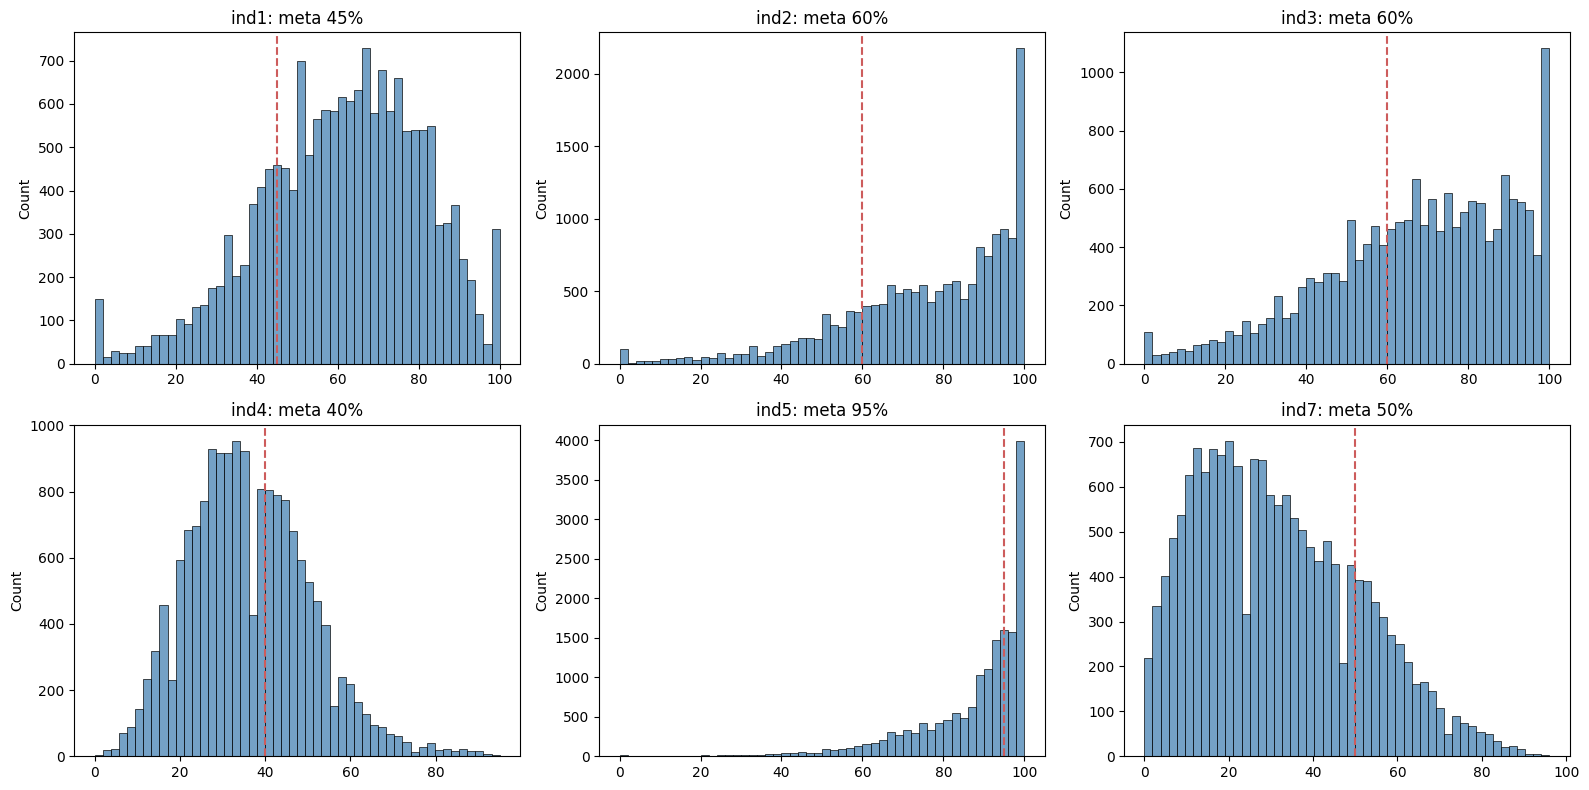

In [8]:
fig, eixos = plt.subplots(2, 3, figsize=(16, 8))
for eixo, (ind, grupo) in zip(eixos.flatten(), df.groupby('indicador')):
    sns.histplot(grupo['vl_perc_quad'], bins=50, ax=eixo, color='steelblue')
    eixo.axvline(METAS[ind], color='indianred', ls='--')
    eixo.set_title(f'{ind}: meta {METAS[ind]}%')
    eixo.set_xlabel('')
plt.tight_layout()
plt.show()

In [9]:
df['bateu_meta'] = df['vl_perc_quad'] >= df['indicador'].map(METAS)
df.groupby(['indicador', 'ds_quadrimestre']).agg(
    mediana=('vl_perc_quad', 'median'),
    bateu_meta=('bateu_meta', 'mean'),
).unstack().round(3)

mediana               bateu_meta              
ds_quadrimestre  2024Q1 2024Q2 2024Q3     2024Q1 2024Q2 2024Q3
indicador                                                     
ind1               64.0   63.0   59.0      0.811  0.806  0.749
ind2               82.0   82.0   75.0      0.825  0.820  0.736
ind3               73.0   71.0   64.0      0.704  0.677  0.576
ind4               35.0   35.0   35.0      0.383  0.398  0.386
ind5               92.0   92.0   91.0      0.398  0.376  0.365
ind7               35.0   29.0   23.0      0.263  0.172  0.147

- **Três indicadores quase todo mundo bate, três quase ninguém.** Pré-natal (ind1), sífilis e HIV (ind2) e saúde bucal da gestante (ind3) ficam acima da meta em 58% a 83% dos municípios. Citopatológico (ind4), vacinação (ind5) e diabetes (ind7) ficam abaixo em mais de 60%.
- **A vacinação tem a meta mais dura:** mediana de 92% contra meta de 95%. Muito município fica perto sem chegar, e 19% batem 100%.
- **O desempenho piora ao longo de 2024.** A mediana cai de Q1 para Q3 em todos os indicadores, exceto o citopatológico. Diabetes cai mais: de 35% para 23%, e a fração que bate a meta vai de 26% para 15%.
- **Picos em 0 e em 100 nos indicadores da gestante.** São municípios pequenos, em que uma gestante muda o resultado em dezenas de pontos, como mostra a seção de outliers.

### Correlação entre os indicadores

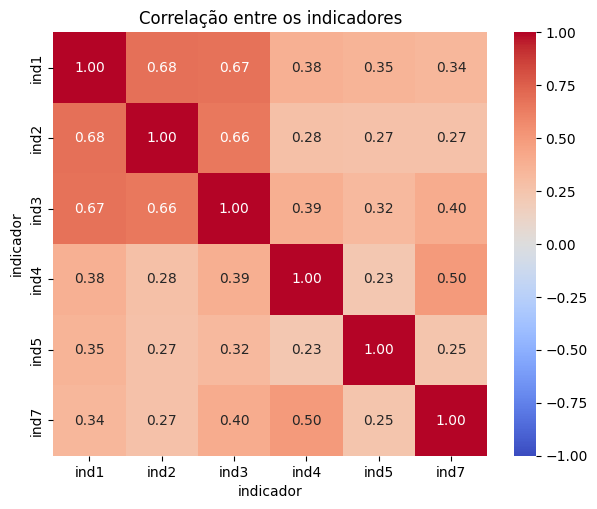

In [10]:
res = df.pivot_table(index=chave, columns='indicador', values='vl_perc_quad')

plt.figure(figsize=(7, 5.5))
sns.heatmap(res.corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlação entre os indicadores')
plt.show()

- **Os três indicadores da gestante andam juntos** (0,66 a 0,68): saem do mesmo pré-natal e usam o mesmo denominador.
- **Citopatológico e diabetes também** (0,50): os dois dependem de consulta e registro na rotina da equipe.
- **Vacinação é o mais independente** (0,23 a 0,35).
- Nenhuma correlação é alta a ponto de um indicador repetir o outro, então os seis ficam no modelo.

### O ISF: a regra da portaria em código

A nota de cada indicador é `resultado / meta * 10`, limitada a 10. O ISF é a média das notas ponderada pelos pesos. Antes de aplicar na base, a função é conferida contra o exemplo da Tabela 1 do manual instrutivo, que dá 8,1.

In [11]:
def calcular_isf(resultado, metas, pesos):
    nota = (resultado / metas).clip(upper=1) * 10
    return (nota * pesos).sum(axis=1) / pesos.sum()

exemplo = pd.DataFrame([[70, 60, 55, 40, 80, 25, 30]], columns=[f'ind{i}' for i in range(1, 8)])
metas_manual = pd.Series([60, 60, 60, 40, 95, 50, 50], index=exemplo.columns)
pesos_manual = pd.Series([1, 1, 2, 1, 2, 2, 1], index=exemplo.columns)
assert round(calcular_isf(exemplo, metas_manual, pesos_manual).iloc[0], 1) == 8.1

isf = calcular_isf(res, METAS, PESOS).rename('isf')
isf.groupby('ds_quadrimestre').describe().round(2)

,count,mean,std,min,25%,50%,75%,max
ds_quadrimestre,,,,,,,,
2024Q1,5568.0,8.75,1.27,1.21,8.24,9.08,9.69,10.0
2024Q2,5568.0,8.64,1.28,1.32,8.14,8.97,9.53,10.0
2024Q3,5568.0,8.32,1.39,0.51,7.65,8.64,9.30,10.0


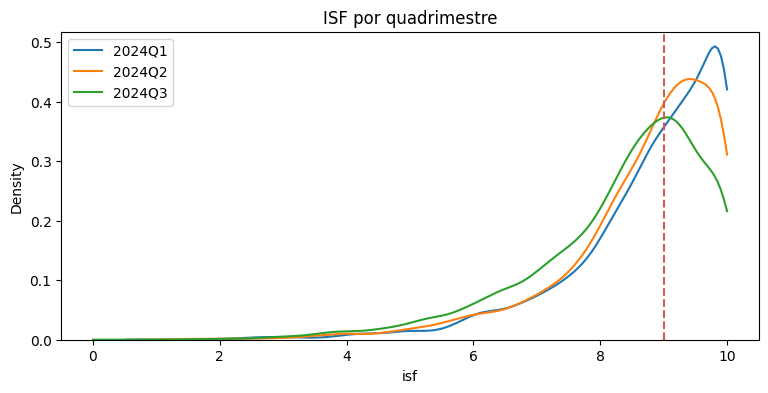

In [12]:
plt.figure(figsize=(9, 4))
for q, grupo in isf.groupby('ds_quadrimestre'):
    sns.kdeplot(grupo, label=q, clip=(0, 10))
plt.axvline(CORTE, color='indianred', ls='--')
plt.title('ISF por quadrimestre')
plt.legend()
plt.show()

- **O ISF é alto e se acumula perto de 10.** A mediana de Q1 é 9,08, e um quarto dos municípios passa de 9,69. A nota de cada indicador para em 10, então quem passa da meta não ganha mais.
- **E cai a cada quadrimestre:** mediana 9,08, 8,97 e 8,64. A curva de Q3 se espalha para a esquerda, puxada por diabetes e pelos indicadores da gestante.
- **O corte em 9 fica no meio da distribuição,** e por isso divide os municípios em duas metades parecidas.

### Relação com o target: o ISF de um quadrimestre e o do seguinte

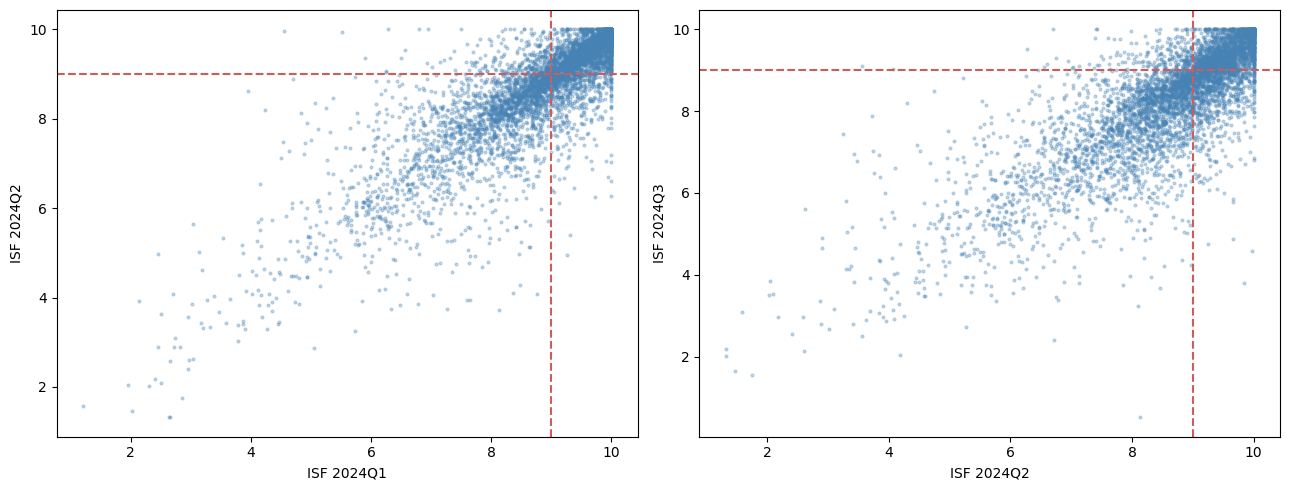

correlação Q1 x Q2: 0.844
correlação Q2 x Q3: 0.806


abaixo de 9 em Q3,False,True
abaixo de 9 em Q2,,
False,1829,886
True,239,2616


In [13]:
largo = isf.unstack('ds_quadrimestre')

fig, eixos = plt.subplots(1, 2, figsize=(13, 5))
for eixo, (t, t1) in zip(eixos, [('2024Q1', '2024Q2'), ('2024Q2', '2024Q3')]):
    eixo.scatter(largo[t], largo[t1], s=4, alpha=0.3, color='steelblue')
    eixo.axvline(CORTE, color='indianred', ls='--')
    eixo.axhline(CORTE, color='indianred', ls='--')
    eixo.set_xlabel(f'ISF {t}')
    eixo.set_ylabel(f'ISF {t1}')
plt.tight_layout()
plt.show()

print('correlação Q1 x Q2:', round(largo['2024Q1'].corr(largo['2024Q2']), 3))
print('correlação Q2 x Q3:', round(largo['2024Q2'].corr(largo['2024Q3']), 3))
pd.crosstab(largo['2024Q2'] < CORTE, largo['2024Q3'] < CORTE, rownames=['abaixo de 9 em Q2'], colnames=['abaixo de 9 em Q3'])

In [14]:
populacao = df.groupby(chave)['populacao'].first().xs('2024Q1', level='ds_quadrimestre')
porte = pd.qcut(populacao, 4, labels=['1º quartil', '2º quartil', '3º quartil', '4º quartil'])
(largo['2024Q2'] - largo['2024Q1']).abs().groupby(porte, observed=True).mean().round(2).rename('variação média do ISF, Q1 para Q2')

populacao
1º quartil    0.62
2º quartil    0.46
3º quartil    0.40
4º quartil    0.34
Name: variação média do ISF, Q1 para Q2, dtype: float64

- **O ISF é persistente:** a correlação entre um quadrimestre e o seguinte é 0,84 (Q1 e Q2) e 0,81 (Q2 e Q3). A maior parte dos pontos fica perto da diagonal.
- **Mas a nuvem é larga perto do corte.** De Q2 para Q3, 886 municípios que tinham 9 ou mais caíram para baixo de 9, e só 239 fizeram o caminho contrário. A previsão "repete o atual" erra justamente esses 1.125.
- **Município pequeno oscila mais.** No quartil de menor população, o ISF varia em média 0,62 ponto de um quadrimestre para o outro; no maior, 0,34. Com poucas gestantes ou poucos diabéticos, uma pessoa a mais ou a menos move o indicador.

### Distribuição do target

In [15]:
(largo < CORTE).mean().round(3)

ds_quadrimestre
2024Q1    0.471
2024Q2    0.513
2024Q3    0.629
dtype: float64

O target é **quase equilibrado no treino** (51,3% abaixo de 9 em Q2) e **mais positivo no teste** (62,9% em Q3). O modelo aprende com uma transição mais calma do que a que vai enfrentar. Por isso:
- a separação de validação é estratificada (`stratify=y`);
- a métrica principal é a **balanced accuracy**, que compara treino e teste mesmo com proporções diferentes;
- também se olha o **recall de `abaixo_90`**, porque deixar passar um município que vai cair custa mais que um alarme falso, e a **AUC**, que não depende do limiar de 0,5.

### Valores faltantes

In [16]:
print('ausentes na base:', df.isna().sum().sum())
print('linhas repetidas (município, quadrimestre, indicador):', df.duplicated(['ibge', 'ds_quadrimestre', 'indicador']).sum())
print('municípios por quadrimestre:', df.groupby('ds_quadrimestre')['ibge'].nunique().to_dict())
print('municípios nos três quadrimestres:', largo.dropna().shape[0])
largo[largo.isna().any(axis=1)]

ausentes na base: 0
linhas repetidas (município, quadrimestre, indicador): 0
municípios por quadrimestre: {'2024Q1': 5568, '2024Q2': 5568, '2024Q3': 5568}
municípios nos três quadrimestres: 5566


,ds_quadrimestre,2024Q1,2024Q2,2024Q3
ibge,uf,,,
150490,PA,NaN,NaN,7.461842
150570,PA,6.485417,NaN,NaN
352760,SP,NaN,6.199306,5.334028
354500,SP,5.881140,7.356469,NaN


Não há valor ausente nem linha repetida. O que falta são municípios: 5.568 dos 5.570 aparecem em cada quadrimestre, e 4 (dois do Pará e dois de São Paulo) não aparecem nos três, provavelmente por não terem equipe válida naquele período. A montagem de treino e teste usa só os municípios presentes nos dois quadrimestres do par, sem imputação.

### Outliers e inconsistências

resultado diferente de numerador / denominador (mais de 1 ponto): 0
denominador zero: 7 | resultado nesses casos: [0.]
identificado acima de 3x o estimado: 923 | máximo: 1800
cadastro maior que a população: 70.6% | máximo: 2.25
resultado em 100%: {'ind1': 0.018, 'ind2': 0.104, 'ind3': 0.058, 'ind4': 0.0, 'ind5': 0.192, 'ind7': 0.0}
gestantes no denominador (mediana): resultado 0 ou 100: 12.0 | resto: 46.0
população (mediana): identificado acima de 3x: 2564.0 | todos: 11065.0


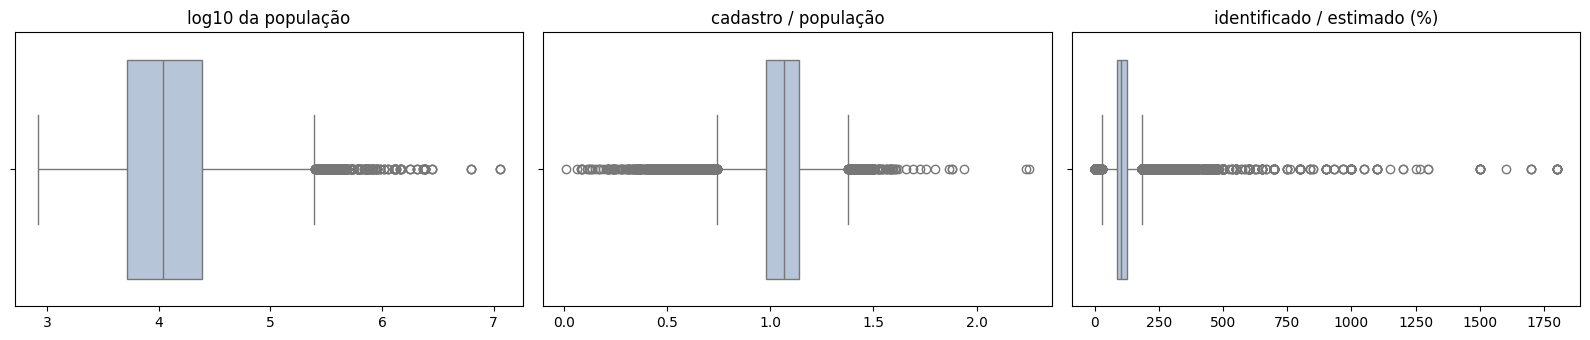

In [17]:
cadastro = df.groupby(chave)[['cadastro', 'populacao']].first()
cobertura = cadastro['cadastro'] / cadastro['populacao']
recalculado = (df['numerador'] / df['denominador_utilizador'] * 100).round()

print('resultado diferente de numerador / denominador (mais de 1 ponto):', (recalculado - df['vl_perc_quad']).abs().gt(1).sum())
print('denominador zero:', (df['denominador_utilizador'] == 0).sum(), '| resultado nesses casos:', df.loc[df['denominador_utilizador'] == 0, 'vl_perc_quad'].unique())
print('identificado acima de 3x o estimado:', (df['percentual'] > 300).sum(), '| máximo:', df['percentual'].max())
print('cadastro maior que a população:', f'{(cobertura > 1).mean():.1%}', '| máximo:', round(cobertura.max(), 2))
print('resultado em 100%:', df['vl_perc_quad'].eq(100).groupby(df['indicador']).mean().round(3).to_dict())

gestante = df[df['indicador'].isin(['ind1', 'ind2', 'ind3'])]
extremo = gestante['vl_perc_quad'].isin([0, 100])
print('gestantes no denominador (mediana): resultado 0 ou 100:', gestante.loc[extremo, 'denominador_utilizador'].median(), '| resto:', gestante.loc[~extremo, 'denominador_utilizador'].median())
print('população (mediana): identificado acima de 3x:', df.loc[df['percentual'] > 300, 'populacao'].median(), '| todos:', df['populacao'].median())

fig, eixos = plt.subplots(1, 3, figsize=(16, 3.5))
sns.boxplot(x=np.log10(cadastro['populacao']), ax=eixos[0], color='lightsteelblue')
sns.boxplot(x=cobertura, ax=eixos[1], color='lightsteelblue')
sns.boxplot(x=df['percentual'], ax=eixos[2], color='lightsteelblue')
for eixo, titulo in zip(eixos, ['log10 da população', 'cadastro / população', 'identificado / estimado (%)']):
    eixo.set_title(titulo)
    eixo.set_xlabel('')
plt.tight_layout()
plt.show()

- **O resultado bate com a conta:** em nenhuma linha `vl_perc_quad` difere de `numerador / denominador` em mais de um ponto.
- **Denominador zero em 7 linhas,** todas com resultado 0. É o município sem nenhuma gestante ou criança identificada no período: o resultado não foi medido, mas entra como 0 e derruba a nota. Fica como está, porque é assim que o ministério calcula.
- **Os picos em 0 e 100 são de municípios pequenos:** a mediana é de 12 gestantes nesses casos, contra 46 no resto.
- **`percentual` chega a 1.800%** (923 linhas acima de 300%). São municípios pequenos (mediana de 2.564 habitantes), em que a estimativa por base externa sai baixa. Não é erro, e só importa abaixo de 85%, onde o cálculo troca de denominador. Por isso a feature usa o corte, e não o valor.
- **Cadastro maior que a população em 70,6% dos registros,** chegando a 2,25 vezes. A população é estimativa do IBGE, e o cadastro inclui gente de outros municípios e cadastros duplicados. Mantido: a razão entra como feature.
- **A população vai de 833 habitantes a 11,4 milhões.** Os outliers do boxplot são as capitais e as cidades grandes. Ficam, porque são municípios reais, e o modelo usa o log.

### Principais insights da EDA

1. **A regra está toda na base.** Com as metas e os pesos das notas técnicas, o ISF de cada município pode ser recalculado, e a função confere com o exemplo do manual.
2. **Citopatológico, vacinação e diabetes decidem o ISF:** são os três que a maioria não bate.
3. **O ISF é persistente, mas 2024 piorou.** A correlação entre quadrimestres fica entre 0,81 e 0,84, com uma queda geral mais forte em Q3.
4. **Município pequeno oscila mais,** porque o denominador é pequeno.
5. **A base é limpa:** sem ausentes nem duplicados, e com resultados coerentes com numerador e denominador. As inconsistências (denominador zero, percentual extremo, cadastro acima da população) vêm da forma como o dado é produzido, não de erro de digitação.

## 4. Tratamento e pré-processamento

Decisões e justificativas:

| Etapa | Decisão | Por quê |
| --- | --- | --- |
| Visão de equipe | só `validas` | é a que conta para o pagamento |
| Indicador 6 | ISF parcial, soma de pesos 8 | não está na base aberta |
| Valores faltantes | nenhum tratamento | não há ausentes; os 4 municípios incompletos saem só do par em que faltam |
| Duplicados | nenhum tratamento | não há linha repetida |
| Denominador zero | mantido, com resultado 0 | é o resultado oficial |
| Outliers | mantidos | capitais, municípios pequenos e cadastro inflado são casos reais, e árvores não dependem de escala |
| Colunas descartadas | `municipio`, `nu_competencia`, `dt_criacao_registro`, `visao_equipe`, numeradores e bases externas | repetem outra coluna ou viram feature |
| Formato | uma linha por município e quadrimestre, um indicador por coluna | o modelo prevê o município, não o indicador |
| Treino e teste | temporal: Q1 para Q2 treina, Q2 para Q3 testa | é a situação de uso real, prever um quadrimestre que ainda não aconteceu |
| Encoding | `uf` em one-hot | ver a seção de encoding |
| Normalização | não aplicada | XGBoost e CatBoost dividem por limiar |

### Feature engineering

**Oportunidades identificadas na EDA:**

- **`isf`.** O ISF atual, pela regra. É uma soma ponderada de notas limitadas a 10, e uma árvore precisaria de muitos cortes para reconstruir.
- **`metas_batidas`.** Quantas das seis metas o município bate hoje.
- **`folga_min`.** A menor folga em relação à meta, em fração (`resultado / meta - 1`). Negativa, mede o tamanho do buraco no pior indicador; perto de zero, aponta quem está no limite.
- **`log_gestantes` e `log_diabeticos`.** O tamanho dos denominadores, que explica a oscilação dos municípios pequenos.
- **`n_estimado`.** Em quantos indicadores o cálculo usou o denominador estimado, ou seja, o identificado ficou abaixo de 85% do estimado. É sinal de registro fraco.
- **`cobertura`.** Cadastro sobre população.
- **`log_pop`.** O porte do município.

In [18]:
den = df.pivot_table(index=chave, columns='indicador', values='denominador_utilizador')
usa_estimado = df.assign(est=df['percentual'] < 85).groupby(chave)['est'].sum()

mun = res.copy()
mun['isf'] = isf
mun['metas_batidas'] = (res >= METAS).sum(axis=1)
mun['folga_min'] = (res / METAS - 1).min(axis=1)
mun['log_gestantes'] = np.log1p(den['ind1'])
mun['log_diabeticos'] = np.log1p(den['ind7'])
mun['n_estimado'] = usa_estimado
mun['cobertura'] = cobertura
mun['log_pop'] = np.log(cadastro['populacao'])
mun = mun.reset_index()

In [19]:
def montar(t, t1):
    atual = mun[mun['ds_quadrimestre'] == t].set_index('ibge')
    seguinte = mun[mun['ds_quadrimestre'] == t1].set_index('ibge')
    comuns = atual.index.intersection(seguinte.index)
    X = atual.loc[comuns].drop(columns='ds_quadrimestre')
    y = (seguinte.loc[comuns, 'isf'] < CORTE).astype(int).rename('abaixo_90')
    return X, y

X_treino, y_treino = montar('2024Q1', '2024Q2')
X_teste, y_teste = montar('2024Q2', '2024Q3')
print('treino (Q1 -> Q2):', X_treino.shape, '| teste (Q2 -> Q3):', X_teste.shape)

treino (Q1 -> Q2): (5567, 15) | teste (Q2 -> Q3): (5567, 15)


### EDA das novas features

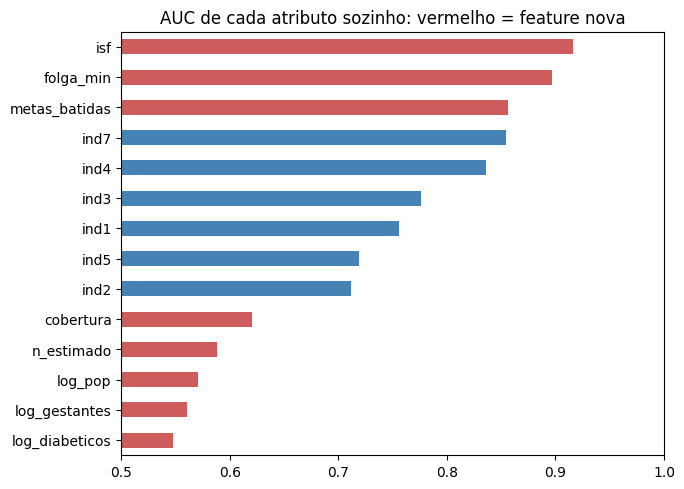

,ind1,ind2,ind3,ind4,ind5,ind7,isf,metas_batidas,folga_min,log_gestantes,log_diabeticos,n_estimado,cobertura,log_pop
abaixo_90,,,,,,,,,,,,,,
0,72.0,90.0,84.0,43.0,96.0,48.0,9.67,5.0,-0.18,3.66,6.92,0.0,1.10,9.24
1,54.0,73.0,60.0,27.0,88.0,22.0,8.33,3.0,-0.62,3.93,7.07,1.0,1.05,9.48


In [20]:
novas = ['isf', 'metas_batidas', 'folga_min', 'log_gestantes', 'log_diabeticos', 'n_estimado', 'cobertura', 'log_pop']
numericas = list(METAS.index) + novas

auc = pd.Series({c: roc_auc_score(y_treino, X_treino[c]) for c in numericas})
separacao = (auc - 0.5).abs().add(0.5).sort_values()
cores = ['indianred' if c in novas else 'steelblue' for c in separacao.index]
separacao.plot.barh(figsize=(7, 5.5), color=cores, xlim=(0.5, 1))
plt.title('AUC de cada atributo sozinho: vermelho = feature nova')
plt.show()

pd.concat([X_treino[numericas], y_treino], axis=1).groupby('abaixo_90').median().round(2)

- **As três features da regra são as que mais separam:** `isf` com AUC de 0,917 sozinho, `folga_min` com 0,897 e `metas_batidas` com 0,856. O melhor indicador isolado, diabetes, fica em 0,854.
- **Entre os indicadores, diabetes e citopatológico separam mais** (0,854 e 0,836), os mesmos que a maioria não bate. Quem fica abaixo de 9 no quadrimestre seguinte tem mediana de 22% em diabetes, contra 48% de quem fica acima.
- **Quem vai ficar abaixo de 9 está longe da meta no pior indicador:** `folga_min` mediana de -0,62, contra -0,18.
- **Porte e registro separam pouco sozinhos** (0,55 a 0,62). Era esperado: eles não dizem se o município vai bem ou mal, dizem quanto ele oscila. O efeito aparece combinado com o ISF, na importância do modelo.

### Encoding e padronização

- **`uf`: one-hot.** É nominal, com 27 valores, e a proporção do target varia muito entre estados. One-hot cria 27 colunas, pouco para árvores.
- **`ibge` vira índice, não atributo:** é só identificador.
- **Padronização não é necessária:** XGBoost e CatBoost dividem por limiar.
- O one-hot é feito separadamente em treino e teste. Isso só vale porque as duas bases têm as mesmas 27 UFs, o que o `assert` confere.

In [21]:
X_treino = pd.get_dummies(X_treino, columns=['uf'], dtype=int)
X_teste = pd.get_dummies(X_teste, columns=['uf'], dtype=int)
assert list(X_treino.columns) == list(X_teste.columns)
print('treino:', X_treino.shape, '| teste:', X_teste.shape)

treino: (5567, 41) | teste: (5567, 41)


## 5. Planejamento

### Algoritmos base

Os candidatos são as famílias de árvores mais fortes em dado tabular, do bagging ao boosting, mais um ensemble. Nenhum deles se justifica se não fizer melhor que a régua.

| Candidato | Família | Por que entra |
| --- | --- | --- |
| **repete o atual** | regra, sem treino | é a régua: prevê que o município fica abaixo de 9 se já está abaixo de 9. O ISF é persistente (correlação de 0,81 a 0,84 entre quadrimestres), então essa régua é forte |
| **Random Forest** | bagging de árvores | captura não linearidade e interação com pouco ajuste, e é robusta a outlier |
| **XGBoost** | boosting de gradiente | referência em dado tabular, com regularização explícita |
| **LightGBM** | boosting de gradiente | mesma família, árvore cresce por folha, treino mais rápido |
| **CatBoost** | boosting de gradiente | boosting ordenado, costuma precisar de menos ajuste |
| **ensemble** | média das probabilidades dos três boosting | testa se combinar os três reduz a variância |

Nenhum candidato precisa de padronização: todos são árvores, que dividem por limiar e não dependem de escala.

### Métricas de sucesso

| Métrica | Papel | Por quê |
| --- | --- | --- |
| **balanced accuracy** | **principal**, decide a escolha | média do recall das duas classes. Não muda com a proporção do target, que vai de 51% no treino para 63% no teste |
| **recall de `abaixo_90`** | obrigatória | deixar passar um município que vai cair é o erro caro: ele perde incentivo sem aviso |
| **AUC** | obrigatória | mede a ordem do risco sem depender do limiar, que é o que importa para uma lista de prioridade |
| precisão e F1 de `abaixo_90` | apoio | mostram o custo do recall em alarmes falsos |

**Critérios de sucesso, fixados antes de abrir o teste:**

1. Superar **"repete o atual"** em balanced accuracy e em recall no teste.
2. Entre os municípios que hoje têm ISF de 9 ou mais, os alertas de queda do modelo acertarem **mais que a taxa de queda do grupo**. É o caso que a régua ingênua nunca aponta.
3. Ser **estável** na validação cruzada: desvio padrão da balanced accuracy abaixo de 0,01 entre as dobras.

### Protocolo

- **Escolha só com o treino.** Os candidatos são comparados por validação cruzada estratificada de 5 dobras sobre os pares Q1 para Q2. Ajuste de hiperparâmetros e de limiar também ficam no treino.
- **Teste aberto uma vez.** Os pares Q2 para Q3 só entram na seção 8, depois da escolha. Se o ranking do teste for diferente, a escolha não muda: trocar de modelo depois de ver o teste seria usar o teste para treinar.

A função abaixo calcula as métricas do planejamento para qualquer conjunto de previsões. Ela é a mesma na validação cruzada e no teste.

In [22]:
def metricas(y, score, previsto):
    """As métricas de sucesso definidas no planejamento, para um conjunto de previsões."""
    return {
        'balanced accuracy': balanced_accuracy_score(y, previsto),
        'recall abaixo_90': recall_score(y, previsto),
        'precisão abaixo_90': precision_score(y, previsto, zero_division=0),
        'F1 abaixo_90': f1_score(y, previsto),
        'AUC': roc_auc_score(y, score),
    }

PRINCIPAIS = ['balanced accuracy', 'recall abaixo_90', 'AUC']

## 6. Modelagem

### 6.1 Quantas árvores: early stopping

Os três boosting param de melhorar em algum ponto e depois começam a decorar o treino. Para achar esse ponto, cada um treina com até 3.000 árvores em 80% do treino e é avaliado nos 20% restantes (separação estratificada). O treino para quando o logloss da validação passa 100 rodadas sem melhorar, e o número de árvores do melhor ponto fica fixo para o resto do caderno.

In [23]:
X_train, X_val, y_train, y_val = train_test_split(
    X_treino, y_treino, test_size=0.2, stratify=y_treino, random_state=RANDOM_STATE
)

In [24]:
PARAMS_XGB = dict(learning_rate=0.03, max_depth=4, min_child_weight=5, subsample=0.8,
                  colsample_bytree=0.8, reg_lambda=1, tree_method='hist',
                  random_state=RANDOM_STATE, n_jobs=-1)
PARAMS_LGBM = dict(learning_rate=0.03, num_leaves=15, min_child_samples=20, subsample=0.8,
                   subsample_freq=1, colsample_bytree=0.8, random_state=RANDOM_STATE, verbose=-1)
PARAMS_CAT = dict(learning_rate=0.03, depth=5, random_seed=RANDOM_STATE, verbose=False,
                  allow_writing_files=False)

xgb_es = XGBClassifier(n_estimators=3000, eval_metric='logloss', early_stopping_rounds=100, **PARAMS_XGB)
xgb_es.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)

lgbm_es = LGBMClassifier(n_estimators=3000, **PARAMS_LGBM)
lgbm_es.fit(X_train, y_train, eval_set=[(X_val, y_val)], callbacks=[lightgbm.early_stopping(100, verbose=False)])

cat_es = CatBoostClassifier(iterations=3000, eval_metric='Logloss', od_type='Iter', od_wait=100, **PARAMS_CAT)
cat_es.fit(X_train, y_train, eval_set=(X_val, y_val))

ARVORES = {
    'XGBoost': xgb_es.best_iteration + 1,
    'LightGBM': lgbm_es.best_iteration_,
    'CatBoost': cat_es.get_best_iteration() + 1,
}
pd.DataFrame({
    'árvores': ARVORES,
    'logloss na validação': {
        'XGBoost': xgb_es.best_score,
        'LightGBM': lgbm_es.best_score_['valid_0']['binary_logloss'],
        'CatBoost': cat_es.get_best_score()['validation']['Logloss'],
    },
}).round(4)

,árvores,logloss na validação
XGBoost,321,0.3087
LightGBM,190,0.3108
CatBoost,551,0.3058


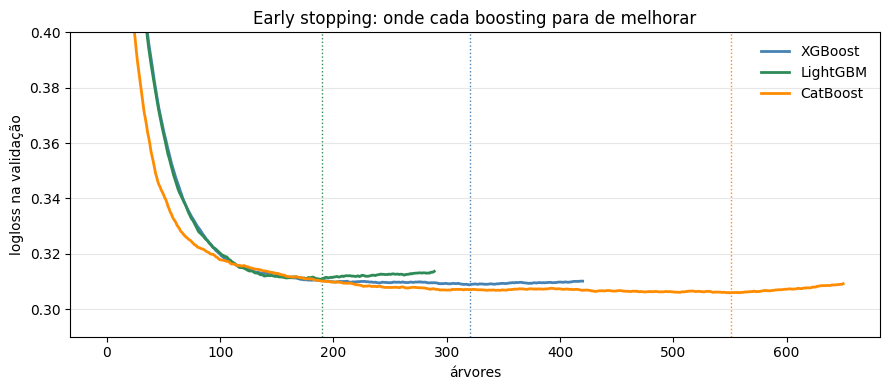

In [25]:
curvas = {
    'XGBoost': xgb_es.evals_result()['validation_0']['logloss'],
    'LightGBM': lgbm_es.evals_result_['valid_0']['binary_logloss'],
    'CatBoost': cat_es.get_evals_result()['validation']['Logloss'],
}
fig, ax = plt.subplots(figsize=(9, 4))
for (nome, curva), cor in zip(curvas.items(), ['steelblue', 'seagreen', 'darkorange']):
    ax.plot(curva, lw=2, color=cor, label=nome)
    ax.axvline(ARVORES[nome], color=cor, ls=':', lw=1)
ax.set_ylim(0.29, 0.40)
ax.set_xlabel('árvores')
ax.set_ylabel('logloss na validação')
ax.set_title('Early stopping: onde cada boosting para de melhorar')
ax.grid(axis='y', alpha=0.3)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

- **Os três chegam ao mesmo logloss** (0,306 a 0,311), por caminhos diferentes: LightGBM em 190 árvores, XGBoost em 321 e CatBoost em 551.
- **Depois do mínimo, a curva sobe devagar.** Treinar além disso só piora a validação, que é o sinal de sobreajuste que o early stopping evita.
- Os hiperparâmetros restantes (profundidade 4 ou 5, amostragem de 80% das linhas e colunas) são valores conservadores para 4.500 linhas de treino. A seção 7.3 testa se ajustá-los compensa.

### 6.2 Os candidatos

Cada candidato é criado do zero por `candidatos()`, para que nenhuma dobra reaproveite um modelo já treinado. O ensemble é uma classe pequena compatível com o scikit-learn, o que permite usar nele a mesma validação cruzada e a mesma importância por permutação dos outros.

In [26]:
class MediaDeModelos(ClassifierMixin, BaseEstimator):
    """Ensemble por média simples das probabilidades de vários classificadores."""

    def __init__(self, modelos):
        self.modelos = modelos

    def fit(self, X, y):
        self.modelos_ = [clone(m).fit(X, y) for m in self.modelos]
        self.classes_ = np.array([0, 1])
        return self

    def predict_proba(self, X):
        return np.mean([m.predict_proba(X) for m in self.modelos_], axis=0)

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] > 0.5).astype(int)


def candidatos():
    """Modelos novos, sem treino, com os hiperparâmetros do planejamento."""
    xgb = XGBClassifier(n_estimators=ARVORES['XGBoost'], **PARAMS_XGB)
    lgbm = LGBMClassifier(n_estimators=ARVORES['LightGBM'], **PARAMS_LGBM)
    cat = CatBoostClassifier(iterations=ARVORES['CatBoost'], **PARAMS_CAT)
    return {
        'Random Forest': RandomForestClassifier(n_estimators=500, min_samples_leaf=5, max_features='sqrt',
                                                n_jobs=-1, random_state=RANDOM_STATE),
        'XGBoost': xgb,
        'LightGBM': lgbm,
        'CatBoost': cat,
        'ensemble': MediaDeModelos([xgb, lgbm, cat]),
    }

list(candidatos())

['Random Forest', 'XGBoost', 'LightGBM', 'CatBoost', 'ensemble']

## 7. Experimentos

### 7.1 Comparação inicial: validação cruzada no treino

Cada candidato treina em 4 dobras e prevê a quinta, cinco vezes. A régua "repete o atual" é avaliada nas mesmas dobras. Além das métricas por dobra, a probabilidade fora da dobra de cada município fica guardada em `oof` para as análises seguintes.

In [27]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

oof = pd.DataFrame(index=X_treino.index, dtype=float)   # probabilidade fora da dobra
linhas = []
for dobra, (i_tr, i_va) in enumerate(cv.split(X_treino, y_treino)):
    X_tr, X_va = X_treino.iloc[i_tr], X_treino.iloc[i_va]
    y_tr, y_va = y_treino.iloc[i_tr], y_treino.iloc[i_va]

    isf_va = X_va['isf']
    oof.loc[X_va.index, 'repete o atual'] = CORTE - isf_va
    linhas.append({'modelo': 'repete o atual', 'dobra': dobra, 'segundos': 0.0,
                   **metricas(y_va, CORTE - isf_va, isf_va < CORTE)})

    for nome, modelo in candidatos().items():
        inicio = time.perf_counter()
        modelo.fit(X_tr, y_tr)
        segundos = time.perf_counter() - inicio
        p = modelo.predict_proba(X_va)[:, 1]
        oof.loc[X_va.index, nome] = p
        linhas.append({'modelo': nome, 'dobra': dobra, 'segundos': segundos, **metricas(y_va, p, p > 0.5)})

cv_res = pd.DataFrame(linhas)
print(len(cv_res), 'avaliações:', cv_res['modelo'].nunique(), 'modelos x 5 dobras')

30 avaliações: 6 modelos x 5 dobras


In [28]:
media = cv_res.groupby('modelo').mean(numeric_only=True).drop(columns='dobra')
desvio = cv_res.groupby('modelo').std(numeric_only=True).drop(columns='dobra')
ordem = media['balanced accuracy'].sort_values(ascending=False).index

tabela_cv = pd.DataFrame(index=ordem)
for m in ['balanced accuracy', 'recall abaixo_90', 'precisão abaixo_90', 'F1 abaixo_90', 'AUC']:
    tabela_cv[m] = [f'{media.loc[i, m]:.3f} ± {desvio.loc[i, m]:.3f}' for i in ordem]
tabela_cv['treino por dobra (s)'] = media.loc[ordem, 'segundos'].round(2)
tabela_cv

,balanced accuracy,recall abaixo_90,precisão abaixo_90,F1 abaixo_90,AUC,treino por dobra (s)
modelo,,,,,,
XGBoost,0.864 ± 0.003,0.843 ± 0.015,0.885 ± 0.011,0.863 ± 0.004,0.936 ± 0.010,0.50
ensemble,0.863 ± 0.002,0.840 ± 0.019,0.886 ± 0.013,0.862 ± 0.004,0.936 ± 0.010,3.16
LightGBM,0.862 ± 0.004,0.838 ± 0.021,0.887 ± 0.011,0.861 ± 0.006,0.935 ± 0.010,0.19
CatBoost,0.861 ± 0.008,0.843 ± 0.017,0.881 ± 0.014,0.861 ± 0.009,0.935 ± 0.009,2.50
Random Forest,0.858 ± 0.006,0.839 ± 0.018,0.878 ± 0.009,0.858 ± 0.007,0.934 ± 0.010,1.68
repete o atual,0.850 ± 0.008,0.813 ± 0.016,0.884 ± 0.007,0.847 ± 0.010,0.917 ± 0.011,0.00


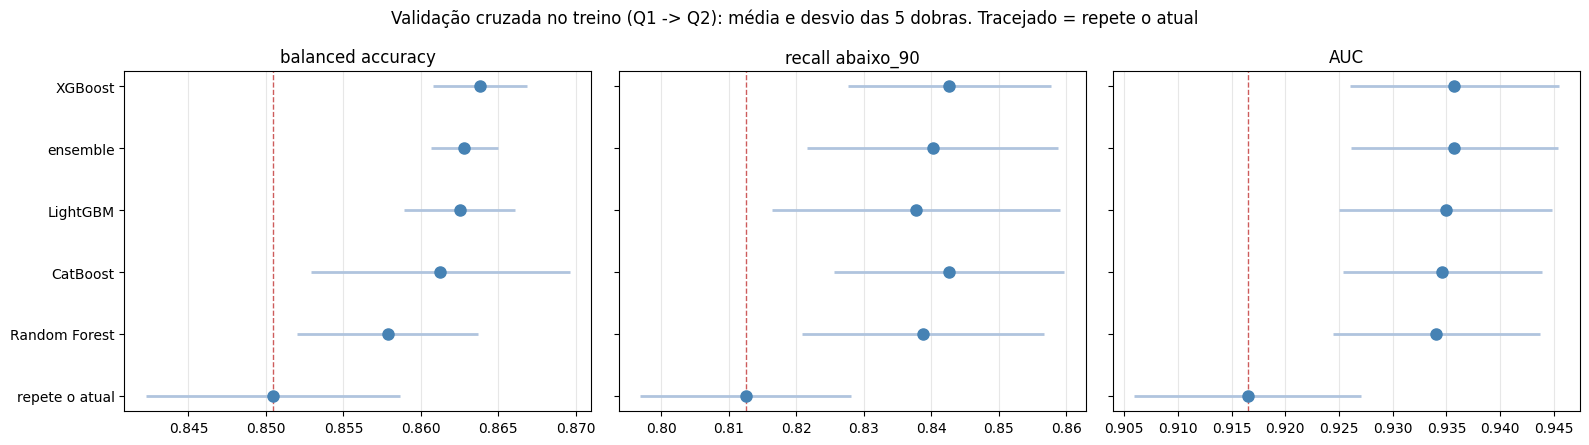

In [29]:
no_grafico = ordem[::-1]
fig, eixos = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for eixo, m in zip(eixos, PRINCIPAIS):
    pontos = cv_res.pivot(index='dobra', columns='modelo', values=m)[no_grafico]
    eixo.errorbar(pontos.mean(), range(len(no_grafico)), xerr=pontos.std(), fmt='o', ms=8,
                  color='steelblue', ecolor='lightsteelblue', elinewidth=2, capsize=0)
    eixo.axvline(pontos['repete o atual'].mean(), color='indianred', ls='--', lw=1)
    eixo.set_yticks(range(len(no_grafico)), no_grafico)
    eixo.set_title(m)
    eixo.grid(axis='x', alpha=0.3)
fig.suptitle('Validação cruzada no treino (Q1 -> Q2): média e desvio das 5 dobras. Tracejado = repete o atual')
plt.tight_layout()
plt.show()

- **Todos os modelos treinados superam a régua:** "repete o atual" fica em 0,850, e os modelos ficam entre 0,858 e 0,864.
- **Os quatro boosting empatam tecnicamente:** de 0,861 a 0,864, com diferenças menores que o desvio entre dobras. O XGBoost lidera por pouco, com o menor desvio entre os modelos individuais (0,003).
- **O ganho sobre a régua é real, mas pequeno:** cerca de 0,013 em balanced accuracy e 0,019 em AUC. A persistência do ISF já explica quase tudo.
- **Custo:** LightGBM e XGBoost treinam em menos de um segundo por dobra. O ensemble custa a soma dos três, várias vezes o XGBoost sozinho, e não ganha nada.

### 7.2 Análise detalhada entre os algoritmos

**Curva ROC.** As curvas usam a probabilidade fora da dobra de todos os municípios do treino.

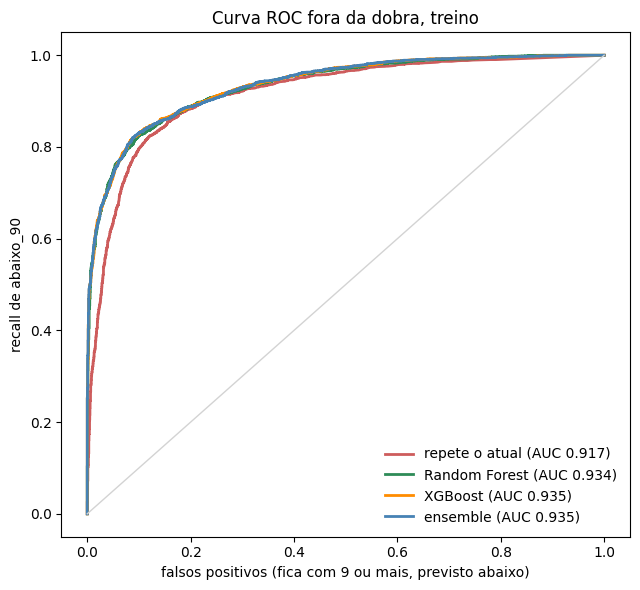

In [30]:
fig, ax = plt.subplots(figsize=(6.5, 6))
mostrar = ['repete o atual', 'Random Forest', 'XGBoost', 'ensemble']
cores = ['indianred', 'seagreen', 'darkorange', 'steelblue']
for nome, cor in zip(mostrar, cores):
    fpr, tpr, _ = roc_curve(y_treino, oof[nome])
    ax.plot(fpr, tpr, lw=2, color=cor, label=f'{nome} (AUC {roc_auc_score(y_treino, oof[nome]):.3f})')
ax.plot([0, 1], [0, 1], color='lightgray', lw=1)
ax.set_xlabel('falsos positivos (fica com 9 ou mais, previsto abaixo)')
ax.set_ylabel('recall de abaixo_90')
ax.set_title('Curva ROC fora da dobra, treino')
ax.legend(frameon=False, loc='lower right')
plt.tight_layout()
plt.show()

As curvas dos modelos de árvore se sobrepõem. **A diferença está toda na parte esquerda,** com poucos alarmes falsos: até uns 20% de falsos positivos, a régua "repete o atual" acha menos municípios que vão cair. Acima de 30%, todas as curvas se juntam. É justamente a região que importa para uma lista curta de prioridade, em que cada alarme falso é uma visita desperdiçada.

**Dobra a dobra.** Um ganho médio pode vir de uma dobra só. A tabela abaixo mostra a diferença de balanced accuracy de cada modelo para a régua, em cada dobra.

In [31]:
# Ganho de cada modelo sobre "repete o atual", dobra a dobra
ganho = {}
base_ba = cv_res[cv_res['modelo'] == 'repete o atual'].set_index('dobra')['balanced accuracy']
for nome in ordem.drop('repete o atual'):
    ba = cv_res[cv_res['modelo'] == nome].set_index('dobra')['balanced accuracy']
    ganho[nome] = ba - base_ba
ganho = pd.DataFrame(ganho).T
ganho['média'] = ganho.mean(axis=1)
ganho['dobras em que vence'] = (ganho.drop(columns='média') > 0).sum(axis=1)
ganho.round(3)

dobra,0,1,2,3,4,média,dobras em que vence
XGBoost,0.021,0.011,0.017,0.006,0.012,0.013,5
ensemble,0.020,0.013,0.019,0.002,0.009,0.012,5
LightGBM,0.021,0.015,0.014,0.007,0.004,0.012,5
CatBoost,0.009,0.010,0.019,-0.001,0.017,0.011,4
Random Forest,0.009,0.013,0.013,-0.002,0.005,0.007,4


- **XGBoost, LightGBM e o ensemble vencem a régua nas 5 dobras.** CatBoost e Random Forest perdem em uma (a dobra 3).
- O XGBoost tem o maior ganho médio (0,013) e o menor ganho por dobra ainda é positivo (0,006).

**O caso que importa.** O valor prático do modelo está em quem hoje tem ISF de 9 ou mais e vai cair, porque a régua ingênua nunca aponta esse município.

In [32]:
# O caso que importa: quem tem ISF de 9 ou mais hoje e cai no quadrimestre seguinte
acima_tr = X_treino['isf'] >= CORTE
y_acima = y_treino[acima_tr]
print(f'municípios com ISF >= 9 em Q1: {acima_tr.sum()} | caíram em Q2: {y_acima.sum()} ({y_acima.mean():.1%})')

linhas = []
for nome in ['Random Forest', 'XGBoost', 'LightGBM', 'CatBoost', 'ensemble']:
    p = oof.loc[acima_tr, nome]
    alerta = p > 0.5
    linhas.append({
        'modelo': nome,
        'alertas': int(alerta.sum()),
        'acertos': int((alerta & (y_acima == 1)).sum()),
        'precisão dos alertas': precision_score(y_acima, alerta, zero_division=0),
        'recall das quedas': recall_score(y_acima, alerta),
        'AUC dentro do grupo': roc_auc_score(y_acima, p),
    })
pd.DataFrame(linhas).set_index('modelo').round(3)

municípios com ISF >= 9 em Q1: 2945 | caíram em Q2: 535 (18.2%)


,alertas,acertos,precisão dos alertas,recall das quedas,AUC dentro do grupo
modelo,,,,,
Random Forest,187,103,0.551,0.193,0.789
XGBoost,217,128,0.590,0.239,0.797
LightGBM,197,116,0.589,0.217,0.794
CatBoost,225,127,0.564,0.237,0.794
ensemble,206,121,0.587,0.226,0.797


- **No treino, 18,2% dos municípios com ISF de 9 ou mais caíram** (535 de 2.945). Essa é a taxa a superar: um alerta ao acaso acertaria 18%.
- **Os boosting acertam de 56% a 59% dos alertas,** três vezes a taxa do grupo. O XGBoost tem a maior precisão (0,590) e a maior AUC dentro do grupo (0,797), empatado com o ensemble.
- **O recall das quedas é baixo em todos** (19% a 24%). A maior parte de quem cai não dá sinal no quadrimestre anterior. Esse limite volta na seção 11.

**Por porte do município.** A EDA mostrou que município pequeno oscila mais. A balanced accuracy abaixo é por quartil de população, fora da dobra.

In [33]:
porte_tr = pd.qcut(X_treino['log_pop'], 4, labels=['1º quartil', '2º quartil', '3º quartil', '4º quartil'])
por_porte = {}
for nome in ['repete o atual', 'Random Forest', 'XGBoost', 'ensemble']:
    previsto = (X_treino['isf'] < CORTE) if nome == 'repete o atual' else (oof[nome] > 0.5)
    por_porte[nome] = pd.Series({
        q: balanced_accuracy_score(y_treino[porte_tr == q], previsto[porte_tr == q])
        for q in porte_tr.cat.categories
    })
pd.DataFrame(por_porte).round(3).rename_axis('porte (população)')

,repete o atual,Random Forest,XGBoost,ensemble
porte (população),,,,
1º quartil,0.791,0.810,0.812,0.810
2º quartil,0.840,0.851,0.860,0.855
3º quartil,0.857,0.868,0.874,0.873
4º quartil,0.902,0.879,0.887,0.893


- **Todos erram mais nos municípios pequenos,** e a régua sofre mais que os modelos: de 0,902 no maior quartil para 0,791 no menor.
- **O ganho dos modelos está nos três primeiros quartis.** É onde o ISF oscila e onde porte, cobertura e tamanho dos denominadores ajudam a dizer quanto ele pode mudar.
- **No maior quartil, ninguém supera a régua,** e o Random Forest fica mais longe dela (0,879 contra 0,902). Nas cidades grandes o ISF quase não muda, e "repete o atual" já é o melhor que se faz.

### 7.3 Ajuste de hiperparâmetros do líder

O XGBoost liderou a comparação. A grade abaixo testa 18 combinações de profundidade, peso mínimo por folha e regularização L2, com a mesma validação cruzada.

In [34]:
# Ajuste fino do líder: grade pequena nos hiperparâmetros que controlam o tamanho e a regularização
# das árvores. Taxa de aprendizado e número de árvores ficam os do early stopping.
grade = GridSearchCV(
    XGBClassifier(n_estimators=ARVORES['XGBoost'], **PARAMS_XGB),
    param_grid={
        'max_depth': [3, 4, 6],
        'min_child_weight': [1, 5, 10],
        'reg_lambda': [1, 10],
    },
    scoring='balanced_accuracy',
    cv=cv,
    n_jobs=1,
)
grade.fit(X_treino, y_treino)

resultado_grade = (
    pd.DataFrame(grade.cv_results_['params'])
    .assign(media=grade.cv_results_['mean_test_score'], desvio=grade.cv_results_['std_test_score'])
    .sort_values('media', ascending=False)
    .reset_index(drop=True)
)
print('configuração do planejamento (max_depth=4, min_child_weight=5, reg_lambda=1):',
      round(resultado_grade.query('max_depth == 4 and min_child_weight == 5 and reg_lambda == 1')['media'].iloc[0], 4))
resultado_grade.round(4).head(8)

configuração do planejamento (max_depth=4, min_child_weight=5, reg_lambda=1): 0.8638


,max_depth,min_child_weight,reg_lambda,media,desvio
0,3,10,1,0.8663,0.0060
1,4,1,10,0.8646,0.0029
2,3,1,1,0.8642,0.0020
3,3,1,10,0.8642,0.0033
4,3,5,10,0.8642,0.0043
5,4,10,1,0.8642,0.0037
6,3,5,1,0.8640,0.0028
7,4,5,1,0.8638,0.0027


- **A melhor combinação da grade** (`max_depth=3`, `min_child_weight=10`, `reg_lambda=1`) chega a 0,8663, contra 0,8638 da configuração do planejamento.
- **A diferença (0,0025) é menor que o desvio entre dobras da própria combinação vencedora (0,006),** que também é o dobro do desvio da configuração original. As oito melhores combinações cabem num intervalo de 0,003.
- **Decisão: manter a configuração do planejamento.** O ganho está dentro do ruído e viria com menos estabilidade. A grade confirma que o resultado não depende de ajuste fino, o que é uma boa notícia sobre a robustez do modelo.

### 7.4 Limiar de decisão

Com o limiar de 0,5, o modelo diz "abaixo de 9" quando a probabilidade passa de 50%. A varredura usa a probabilidade fora da dobra do XGBoost, ainda só no treino.

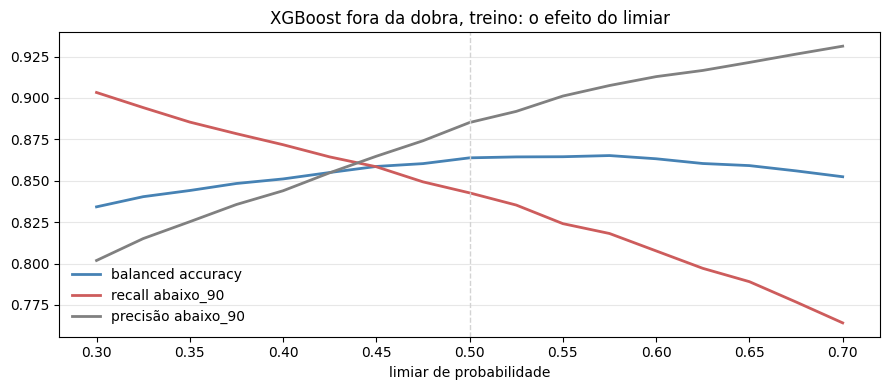

limiar com maior balanced accuracy no treino: 0.575


,balanced accuracy,recall abaixo_90,precisão abaixo_90
limiar,,,
0.40,0.851,0.872,0.844
0.45,0.859,0.858,0.865
0.50,0.864,0.843,0.885
0.55,0.865,0.824,0.901
0.60,0.863,0.808,0.913


In [35]:
limiares = np.round(np.arange(0.30, 0.71, 0.025), 3)
varredura = pd.DataFrame([
    {'limiar': t, **metricas(y_treino, oof['XGBoost'], oof['XGBoost'] > t)} for t in limiares
]).set_index('limiar')

fig, ax = plt.subplots(figsize=(9, 4))
for m, cor in [('balanced accuracy', 'steelblue'), ('recall abaixo_90', 'indianred'), ('precisão abaixo_90', 'gray')]:
    ax.plot(varredura.index, varredura[m], lw=2, color=cor, label=m)
ax.axvline(0.5, color='lightgray', ls='--', lw=1)
ax.set_xlabel('limiar de probabilidade')
ax.set_title('XGBoost fora da dobra, treino: o efeito do limiar')
ax.grid(axis='y', alpha=0.3)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

print('limiar com maior balanced accuracy no treino:', varredura['balanced accuracy'].idxmax())
varredura.loc[[0.4, 0.45, 0.5, 0.55, 0.6], ['balanced accuracy', 'recall abaixo_90', 'precisão abaixo_90']].round(3)

- **A balanced accuracy é plana entre 0,45 e 0,60.** O melhor limiar no treino é 0,575, com 0,865, contra 0,864 em 0,5. Não compensa mudar.
- **O limiar é uma alavanca de uso, não de desempenho.** Baixar para 0,45 sobe o recall de 0,843 para 0,858 e custa 2 pontos de precisão. Se a gestão preferir não deixar ninguém cair sem aviso, esse é o botão.
- **Decisão: limiar 0,5.** Fica explícito como parâmetro (`LIMIAR`) na seção 9.

## 8. Avaliação no teste (Q2 para Q3)

Agora, e só agora, os candidatos treinam com todo o treino (Q1 para Q2) e preveem o teste (Q2 para Q3), um quadrimestre que nenhum deles viu.

In [36]:
modelos = candidatos()
for nome, modelo in modelos.items():
    modelo.fit(X_treino, y_treino)

p_teste = pd.DataFrame({nome: m.predict_proba(X_teste)[:, 1] for nome, m in modelos.items()}, index=X_teste.index)

resultado_teste = {'repete o atual': metricas(y_teste, CORTE - X_teste['isf'], X_teste['isf'] < CORTE)}
for nome in modelos:
    resultado_teste[nome] = metricas(y_teste, p_teste[nome], p_teste[nome] > 0.5)
resultado_teste = pd.DataFrame(resultado_teste).T.loc[ordem]
resultado_teste.round(3)

,balanced accuracy,recall abaixo_90,precisão abaixo_90,F1 abaixo_90,AUC
modelo,,,,,
XGBoost,0.821,0.767,0.911,0.833,0.900
ensemble,0.820,0.765,0.912,0.832,0.901
LightGBM,0.820,0.765,0.912,0.832,0.902
CatBoost,0.821,0.766,0.912,0.833,0.901
Random Forest,0.822,0.775,0.909,0.837,0.903
repete o atual,0.816,0.747,0.917,0.823,0.887


- **Todos os modelos treinados superam a régua no teste,** em balanced accuracy, recall e AUC.
- **O ranking embaralha, e as diferenças viram ruído:** Random Forest, XGBoost e CatBoost ficam entre 0,820 e 0,822. O Random Forest termina 0,001 à frente. Como combinado no protocolo, isso não muda a escolha: a diferença é menor que o desvio da validação cruzada, e trocar de modelo agora seria escolher pelo teste.
- **O XGBoost contra a régua:** balanced accuracy de 0,821 contra 0,816, recall de 0,767 contra 0,747 e AUC de 0,900 contra 0,887.

**Validação cruzada contra teste.** O desempenho cai do treino para o teste. A pergunta é se o modelo sobreajustou ou se o teste é mais difícil.

In [37]:
pd.DataFrame({
    'BA validação cruzada': media.loc[ordem, 'balanced accuracy'],
    'BA teste': resultado_teste['balanced accuracy'],
    'AUC validação cruzada': media.loc[ordem, 'AUC'],
    'AUC teste': resultado_teste['AUC'],
}).round(3)

,BA validação cruzada,BA teste,AUC validação cruzada,AUC teste
modelo,,,,
XGBoost,0.864,0.821,0.936,0.900
ensemble,0.863,0.820,0.936,0.901
LightGBM,0.862,0.820,0.935,0.902
CatBoost,0.861,0.821,0.935,0.901
Random Forest,0.858,0.822,0.934,0.903
repete o atual,0.850,0.816,0.917,0.887


- **A queda é do período, não do modelo:** a régua "repete o atual", que não treina nada, cai na mesma proporção (0,850 para 0,816) que o XGBoost (0,864 para 0,821).
- **Q3 foi um quadrimestre de queda geral.** A fração abaixo de 9 subiu de 51% para 63%, e a mediana de todos os indicadores, menos o citopatológico, piorou. Um modelo treinado numa transição mais calma subestima uma transição pior, e nenhum dos atributos de Q2 avisava disso.

## 9. Modelo final: XGBoost

**Escolha: XGBoost com a configuração do planejamento** (321 árvores, taxa de aprendizado 0,03, profundidade 4, `min_child_weight=5`, amostragem de 80% das linhas e das colunas) **e limiar de 0,5.**

**Por quê:**

1. **Maior balanced accuracy na validação cruzada** (0,864), que é a métrica principal definida no planejamento.
2. **Estável:** menor desvio entre os modelos individuais (0,003) e vitória sobre a régua nas 5 dobras.
3. **Melhor no caso que importa:** maior precisão dos alertas (0,590) e maior AUC (0,797) entre quem hoje tem ISF de 9 ou mais.
4. **Simples e barato:** treina em menos de um segundo. O ensemble empata e custa a soma dos três modelos. CatBoost e LightGBM empatam, mas o XGBoost ficou à frente nos três critérios acima.
5. **Não depende de ajuste fino:** a grade e a varredura de limiar não acharam ganho fora do ruído.

**Por que não os outros:** o Random Forest termina 0,001 à frente no teste, mas foi pior na validação cruzada e perdeu em uma dobra.

**Critérios de sucesso:**

| Critério | Resultado | Atingido? |
| --- | --- | --- |
| superar a régua em balanced accuracy e recall no teste | 0,821 contra 0,816 e 0,767 contra 0,747 | sim, por margem pequena |
| alertas de queda acertarem mais que a taxa do grupo | 65,2% contra 32,6% | sim, o dobro |
| desvio da balanced accuracy abaixo de 0,01 | 0,003 | sim |

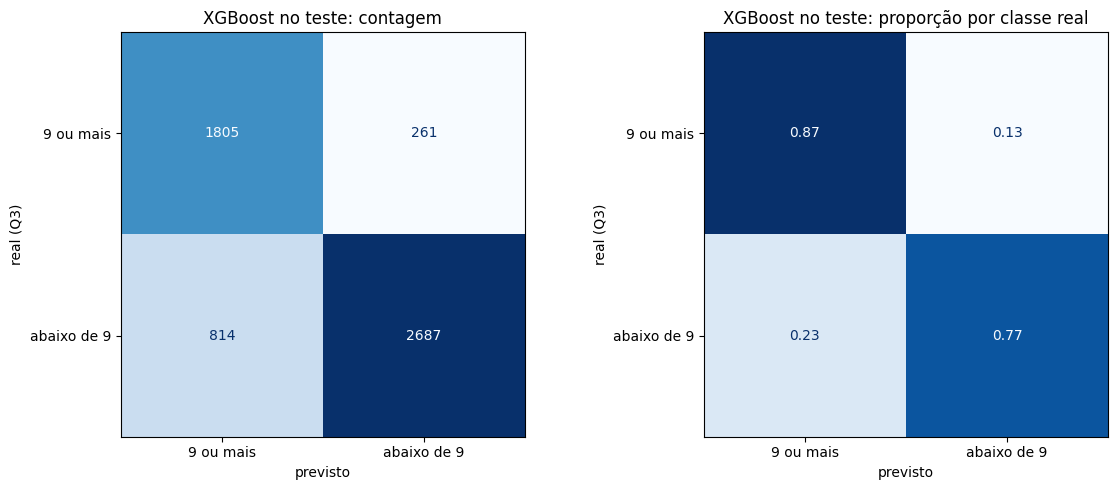

In [38]:
LIMIAR = 0.5
modelo_final = modelos['XGBoost']
p_final = p_teste['XGBoost']
previsto_final = (p_final > LIMIAR).astype(int)

fig, eixos = plt.subplots(1, 2, figsize=(12, 5))
for eixo, normalizar, fmt, titulo in [(eixos[0], None, 'd', 'contagem'), (eixos[1], 'true', '.2f', 'proporção por classe real')]:
    ConfusionMatrixDisplay.from_predictions(
        y_teste, previsto_final, display_labels=['9 ou mais', 'abaixo de 9'],
        normalize=normalizar, values_format=fmt, cmap='Blues', colorbar=False, ax=eixo,
    )
    eixo.set_title(f'XGBoost no teste: {titulo}')
    eixo.set_xlabel('previsto')
    eixo.set_ylabel('real (Q3)')
plt.tight_layout()
plt.show()

- **O modelo acerta 87% de quem fica com 9 ou mais e 77% de quem fica abaixo.**
- **O erro mais comum é o falso negativo:** 814 municípios previstos com 9 ou mais que ficaram abaixo, contra 261 falsos positivos. É o mesmo efeito da queda geral de Q3: o modelo foi otimista num quadrimestre que piorou para todos.

**Entre quem tem ISF de 9 ou mais hoje:**

In [39]:
acima = X_teste['isf'] >= CORTE
quedas = y_teste[acima]
alerta = p_final[acima] > LIMIAR
print(f'ISF >= 9 em Q2: {acima.sum()} | caíram em Q3: {quedas.sum()} ({quedas.mean():.1%})')
print(f'alertas do modelo: {alerta.sum()} | acertos: {(alerta & (quedas == 1)).sum()} '
      f'| precisão: {precision_score(quedas, alerta):.1%} | recall: {recall_score(quedas, alerta):.1%}')
pd.crosstab(quedas, alerta, rownames=['abaixo de 9 em Q3'], colnames=['modelo prevê queda'])

ISF >= 9 em Q2: 2713 | caíram em Q3: 885 (32.6%)
alertas do modelo: 187 | acertos: 122 | precisão: 65.2% | recall: 13.8%


modelo prevê queda,False,True
abaixo de 9 em Q3,,
0,1763,65
1,763,122


- **Dos 2.713 municípios com ISF de 9 ou mais em Q2, 885 caíram em Q3** (32,6%). A régua ingênua não aponta nenhum deles.
- **O modelo aponta 187, e 122 caem de fato: 65% de acerto,** o dobro da taxa do grupo.
- **Mas deixa passar 763,** o que dá recall de 13,8% nesse grupo. A lista é curta e certeira, não completa.

**Como lista de prioridade.** Na prática, a gestão não usa um limiar: ordena pelo risco e olha os primeiros. A tabela mostra quantos dos N primeiros caíram de fato.

In [40]:
# Uso como lista de prioridade: os N municípios com maior risco entre os que hoje estão com 9 ou mais
risco = p_final[acima].sort_values(ascending=False)
taxa_base = quedas.mean()
pd.DataFrame({
    n: {'municípios': n, 'caíram de fato': int(quedas[risco.index[:n]].sum()),
        'precisão': quedas[risco.index[:n]].mean(), 'vezes a taxa do grupo': quedas[risco.index[:n]].mean() / taxa_base}
    for n in [50, 100, 200, 400]
}).T.round(2)

,municípios,caíram de fato,precisão,vezes a taxa do grupo
50,50.0,35.0,0.70,2.15
100,100.0,71.0,0.71,2.18
200,200.0,129.0,0.64,1.98
400,400.0,239.0,0.60,1.83


Entre os 100 municípios de maior risco que hoje estão com 9 ou mais, **71 caem no quadrimestre seguinte**, 2,2 vezes a taxa do grupo. Mesmo nos 400 primeiros, a precisão fica em 60%. Para quem tem equipe limitada para visitar ou apoiar municípios, essa ordem é o produto do modelo.

## 10. Interpretação dos resultados

### 10.1 Feature importance

Duas leituras, porque cada uma tem um viés. A **importância por ganho** do XGBoost mede quanto cada atributo melhorou as divisões no treino, e favorece atributos usados em muitos cortes. A **importância por permutação** embaralha um atributo de cada vez no teste e mede quanto a AUC cai. Ela mostra o que o modelo realmente usa num período que não viu, mas divide o crédito entre atributos correlacionados: se dois carregam a mesma informação, embaralhar um não derruba nada.

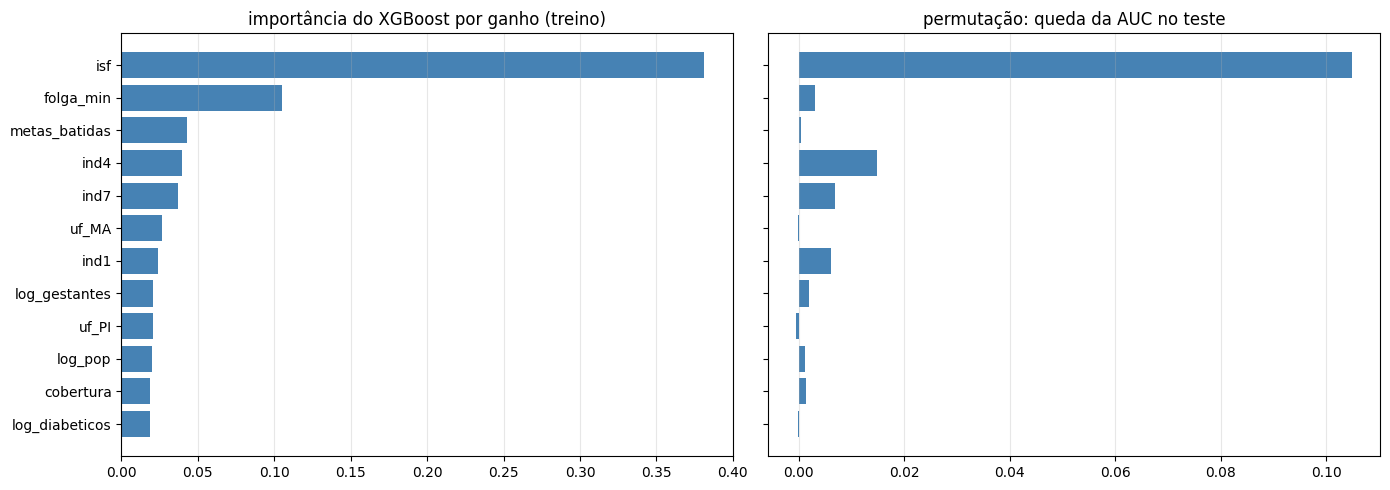

,XGBoost (ganho),permutação (AUC)
isf,0.381,0.105
folga_min,0.105,0.003
metas_batidas,0.043,0.000
ind4,0.040,0.015
ind7,0.037,0.007
uf_MA,0.027,-0.000
ind1,0.024,0.006
log_gestantes,0.021,0.002
uf_PI,0.020,-0.001
log_pop,0.020,0.001


In [41]:
nativa = pd.Series(modelo_final.feature_importances_, index=X_treino.columns)
perm = permutation_importance(modelo_final, X_teste, y_teste, scoring='roc_auc', n_repeats=10,
                              random_state=RANDOM_STATE, n_jobs=1)
permutacao = pd.Series(perm.importances_mean, index=X_teste.columns)

top = nativa.sort_values(ascending=False).head(12).index
fig, eixos = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
eixos[0].barh(top[::-1], nativa[top[::-1]], color='steelblue')
eixos[0].set_title('importância do XGBoost por ganho (treino)')
eixos[1].barh(top[::-1], permutacao[top[::-1]], color='steelblue')
eixos[1].set_title('permutação: queda da AUC no teste')
for eixo in eixos:
    eixo.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

pd.DataFrame({'XGBoost (ganho)': nativa, 'permutação (AUC)': permutacao}).loc[top].round(3)

- **O ISF atual domina as duas leituras:** 38% do ganho, e embaralhá-lo derruba a AUC em 0,105. O modelo parte da régua "repete o atual" e a corrige.
- **A correção vem do citopatológico (ind4) e do diabetes (ind7).** Na permutação, são os dois indicadores que mais pesam depois do ISF (0,015 e 0,007). São também os dois que a maioria dos municípios não bate. Dois municípios com o mesmo ISF vão para lados diferentes conforme estão nesses dois.
- **`folga_min` e `metas_batidas` são importantes no ganho, mas quase zero na permutação.** Repetem informação do ISF e dos indicadores, então embaralhar um deles não faz falta. Isso não quer dizer que sejam inúteis, quer dizer que são redundantes.
- **A UF aparece (Maranhão e Piauí) no ganho e some na permutação:** efeitos regionais que ajudaram a ajustar o treino e não se repetiram no teste.

### 10.2 Exemplos de erros do modelo

**Falsos negativos mais confiantes:** o modelo deu menos de 2% de chance de ficar abaixo de 9, e ficou. Em todas as tabelas de erro, as colunas da esquerda são de Q2 (o que o modelo viu) e as da direita, de Q3 (o que aconteceu).

In [42]:
nomes = df.drop_duplicates('ibge').set_index('ibge')['municipio']
q3 = mun[mun['ds_quadrimestre'] == '2024Q3'].set_index('ibge')
colunas = ['isf', 'ind4', 'ind5', 'ind7', 'log_pop']

def exemplos(mascara, ascendente):
    sel = p_final[mascara].sort_values(ascending=ascendente).head(5).index
    tabela = X_teste.loc[sel, colunas].copy()
    tabela.insert(0, 'município', nomes[sel].values)
    tabela['população'] = np.exp(tabela.pop('log_pop')).round().astype(int)
    tabela['prob. abaixo de 9'] = p_final[sel]
    tabela['ISF em Q3'] = q3.loc[sel, 'isf']
    tabela['ind7 em Q3'] = q3.loc[sel, 'ind7']
    tabela['ind4 em Q3'] = q3.loc[sel, 'ind4']
    return tabela.round(2)

falso_negativo = (y_teste == 1) & (previsto_final == 0)
falso_positivo = (y_teste == 0) & (previsto_final == 1)
print('falsos negativos (previsto 9 ou mais, ficou abaixo):', falso_negativo.sum())
exemplos(falso_negativo, ascendente=True)

falsos negativos (previsto 9 ou mais, ficou abaixo): 814


,município,isf,ind4,ind5,ind7,população,prob. abaixo de 9,ISF em Q3,ind7 em Q3,ind4 em Q3
ibge,,,,,,,,,,
353520,PALMEIRA D'OESTE,10.00,43.0,100.0,50.0,8903,0.02,8.99,15.0,42.0
292660,RIBEIRA DO POMBAL,9.85,53.0,96.0,44.0,53566,0.02,8.62,20.0,52.0
315920,SANTA RITA DE CALDAS,9.95,44.0,93.0,58.0,8460,0.02,8.89,49.0,47.0
430020,AJURICABA,10.00,41.0,96.0,55.0,6720,0.02,8.65,55.0,42.0
320030,ALFREDO CHAVES,10.00,50.0,100.0,53.0,13836,0.02,8.91,46.0,49.0


Municípios com ISF 10 ou perto disso, todos os indicadores acima da meta em Q2, que caíram para entre 8,6 e 9,0. Em Palmeira d'Oeste (SP) o diabetes foi de 50% para 15% em um quadrimestre. Em Ribeira do Pombal (BA), de 44% para 20%. Nada em Q2 sinalizava isso: são quedas bruscas, provavelmente de registro ou de mudança na equipe, que o dado agregado não mostra.

**Falsos positivos mais confiantes:** o modelo deu 98% ou mais de chance de ficar abaixo de 9, e não ficou.

In [43]:
print('falsos positivos (previsto abaixo de 9, ficou com 9 ou mais):', falso_positivo.sum())
exemplos(falso_positivo, ascendente=False)

falsos positivos (previsto abaixo de 9, ficou com 9 ou mais): 261


,município,isf,ind4,ind5,ind7,população,prob. abaixo de 9,ISF em Q3,ind7 em Q3,ind4 em Q3
ibge,,,,,,,,,,
291660,ITAPITANGA,7.80,27.0,89.0,9.0,10279,0.99,9.76,55.0,37.0
210030,ALDEIAS ALTAS,6.95,54.0,60.0,8.0,23286,0.99,9.23,37.0,48.0
431177,MAQUINÉ,7.38,23.0,90.0,16.0,7418,0.99,9.06,34.0,26.0
130020,ATALAIA DO NORTE,8.13,27.0,83.0,4.0,15314,0.99,9.40,49.0,30.0
411660,NOVA AMÉRICA DA COLINA,8.24,28.0,89.0,1.0,3280,0.98,9.39,42.0,27.0


O padrão inverso: municípios com diabetes quase zerado em Q2 (de 1% a 16%) que saltaram para 34% a 55% em Q3 e subiram o ISF para mais de 9. Em Nova América da Colina (PR), o diabetes foi de 1% para 42%. Um salto desses em quatro meses é típico de quem corrigiu o registro, não de quem mudou o cuidado. O indicador de diabetes é o mais volátil da base, e o modelo erra quando ele muda de patamar.

**Onde os erros se concentram:**

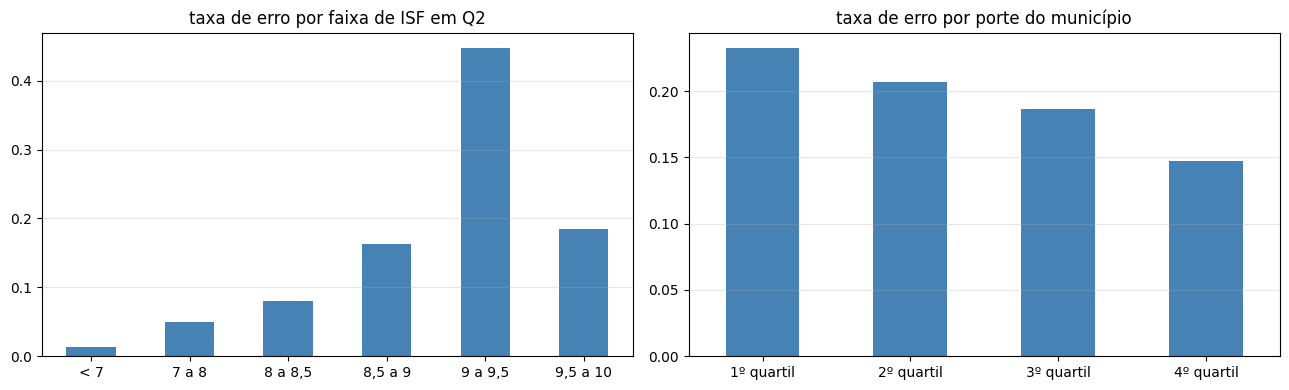

,municípios,taxa de erro,falsos negativos,falsos positivos
isf,,,,
< 7,575,0.014,0,8
7 a 8,656,0.050,3,30
"8 a 8,5",682,0.081,10,45
"8,5 a 9",949,0.163,40,115
"9 a 9,5",1237,0.447,494,59
"9,5 a 10",1468,0.185,267,4


In [44]:
erro = (previsto_final != y_teste)
porte_te = pd.qcut(X_teste['log_pop'], 4, labels=['1º quartil', '2º quartil', '3º quartil', '4º quartil'])
faixa_isf = pd.cut(X_teste['isf'], [0, 7, 8, 8.5, 9, 9.5, 10.01], labels=['< 7', '7 a 8', '8 a 8,5', '8,5 a 9', '9 a 9,5', '9,5 a 10'])

fig, eixos = plt.subplots(1, 2, figsize=(13, 4))
erro.groupby(faixa_isf, observed=True).mean().plot.bar(ax=eixos[0], color='steelblue', rot=0)
eixos[0].set_title('taxa de erro por faixa de ISF em Q2')
eixos[0].set_xlabel('')
erro.groupby(porte_te, observed=True).mean().plot.bar(ax=eixos[1], color='steelblue', rot=0)
eixos[1].set_title('taxa de erro por porte do município')
eixos[1].set_xlabel('')
for eixo in eixos:
    eixo.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

pd.DataFrame({
    'municípios': faixa_isf.value_counts().sort_index(),
    'taxa de erro': erro.groupby(faixa_isf, observed=True).mean(),
    'falsos negativos': falso_negativo.groupby(faixa_isf, observed=True).sum(),
    'falsos positivos': falso_positivo.groupby(faixa_isf, observed=True).sum(),
}).round(3)

- **Perto do corte.** A taxa de erro é de 1,4% para quem está abaixo de 7 e de **44,7% na faixa de 9 a 9,5**, que tem 1.237 municípios e 494 dos 814 falsos negativos. Quem está logo acima do corte cai ou não cai por detalhes que o modelo não vê.
- **Nos municípios pequenos.** O erro vai de 23% no menor quartil de população para 15% no maior, o mesmo efeito de denominador pequeno visto na EDA.

**Por que os falsos negativos caíram:** a tabela compara a variação mediana de cada indicador de Q2 para Q3.

In [45]:
# A queda de Q3 foi geral? Diferença média de cada indicador entre Q2 e Q3, nos falsos negativos e no resto
q2 = mun[mun['ds_quadrimestre'] == '2024Q2'].set_index('ibge')
indicadores = list(METAS.index)
delta = (q3.loc[X_teste.index, indicadores] - q2.loc[X_teste.index, indicadores])
pd.DataFrame({
    'falsos negativos': delta[falso_negativo].median(),
    'acertos que ficaram abaixo': delta[(y_teste == 1) & (previsto_final == 1)].median(),
    'ficaram com 9 ou mais': delta[y_teste == 0].median(),
}).round(1).rename_axis('variação mediana Q2 -> Q3 (pontos)')

,falsos negativos,acertos que ficaram abaixo,ficaram com 9 ou mais
variação mediana Q2 -> Q3 (pontos),,,
ind1,-9.0,-3.0,0.0
ind2,-8.0,-4.0,0.0
ind3,-13.0,-4.0,-2.0
ind4,-1.0,0.0,0.0
ind5,-6.0,0.0,0.0
ind7,-10.0,-3.0,-2.0


**Os falsos negativos são quedas largas, em vários indicadores ao mesmo tempo:** mediana de 8 a 13 pontos a menos nos três indicadores da gestante e 10 no diabetes. Quem caiu e foi previsto caiu pouco (3 a 4 pontos). É um choque que atinge o município inteiro, não um indicador fraco que piora, e por isso não aparece nos atributos do quadrimestre anterior.

## 11. Análise crítica

### Pontos fortes

- **A regra está em código conferível.** `calcular_isf` reproduz o exemplo do manual instrutivo (8,1), e o target sai da regra oficial, não de uma coluna pronta.
- **Validação honesta.** O teste é temporal (prever um quadrimestre que ainda não aconteceu), a escolha do modelo, do hiperparâmetro e do limiar usou só o treino, e o teste foi aberto uma vez.
- **Comparação contra uma régua forte.** "Repete o atual" já acerta 82% no teste. Todo número do caderno é lido contra ela, e não contra o acaso.
- **Útil como lista de prioridade.** Entre quem hoje está bem, os 100 de maior risco caem 2,2 vezes mais que a média do grupo.
- **Leve e estável.** Treina em menos de um segundo, varia 0,003 entre dobras e não depende de ajuste fino.

### Limitações

- **O ganho sobre a régua é pequeno:** 0,005 de balanced accuracy e 0,013 de AUC no teste. A persistência do ISF explica quase tudo, e o modelo é um ajuste fino em cima dela.
- **Não antecipa choques gerais.** A piora de Q3 atingiu o país inteiro e não estava nos dados de Q2. O modelo subestima a queda quando o período muda.
- **Recall baixo entre quem está bem:** de 885 quedas entre os municípios com ISF de 9 ou mais, o modelo avisa 122 no limiar de 0,5.
- **Um único par de treino.** Com três quadrimestres, há um par para treinar (Q1 para Q2) e um para testar (Q2 para Q3). A validação cruzada é dentro do mesmo período, e por isso fica otimista (0,864 contra 0,821 no teste).
- **ISF parcial.** Sem o indicador 6 (hipertensão, peso 2), o ISF tem soma de pesos 8 em vez de 10. O corte em 9 não é exatamente o do pagamento.

### Qualidade dos dados

- **Boa no que existe:** nenhum valor ausente, nenhuma linha repetida, e o resultado de cada indicador bate com numerador sobre denominador em todas as linhas.
- **Falta um indicador inteiro** (o 6) e faltam quatro municípios em algum quadrimestre.
- **Ruído de denominador pequeno:** município com 12 gestantes muda o resultado em 8 pontos com uma gestante a mais. Os picos em 0 e 100 vêm daí.
- **Inconsistências de origem, não de digitação:** denominador zero vira resultado 0 (7 linhas), o identificado chega a 18 vezes o estimado, e o cadastro passa da população em 70,6% dos registros.
- **Dado agregado demais para explicar a queda:** a base não tem número de equipes, troca de profissional, sistema de registro ou repasse, que é onde os choques dos falsos negativos provavelmente nascem.

### Problemas encontrados

| Problema | Como foi tratado |
| --- | --- |
| Prever o ISF do mesmo quadrimestre só reaprenderia a soma ponderada | o target passou a ser o quadrimestre seguinte |
| Proporção do target muda de 51% para 63% entre treino e teste | balanced accuracy como métrica principal |
| Só três quadrimestres | validação cruzada dentro do par de treino, e o otimismo dela foi medido contra o teste |
| O Random Forest terminou 0,001 à frente no teste | a escolha foi mantida pelo protocolo: decidir pelo teste vazaria o teste para a seleção |
| A grade achou uma combinação 0,0025 melhor, mas menos estável | configuração original mantida, porque o ganho está dentro do ruído |
| Diabetes oscila de patamar de um quadrimestre para outro | identificado como a principal fonte de falsos positivos, ver melhorias |
| O CatBoost grava a pasta `catboost_info/` a cada treino | `allow_writing_files=False` |

### Possíveis melhorias futuras

1. **Mais quadrimestres.** O mesmo portal tem 2022 e 2023. Com eles, haveria vários pares de treino, validação por janela deslizante (treinar no passado, validar no seguinte) e atributos de tendência, como a variação do ISF nos dois últimos quadrimestres.
2. **Atributos de volatilidade:** desvio do indicador de diabetes ao longo do tempo e mudança de denominador, para separar quem melhorou o cuidado de quem corrigiu o registro.
3. **Dados externos por município:** número de equipes e de profissionais (CNES), cobertura da atenção primária, IDH e repasses. São candidatos a explicar os choques que hoje viram falso negativo.
4. **Incluir o indicador 6,** se for obtido, para o ISF ficar completo e o corte em 9 coincidir com o do pagamento.
5. **Limiar por custo.** Com o custo de uma visita e o valor do incentivo perdido, o limiar pode sair de uma conta, e não da convenção de 0,5. As probabilidades também podem ser calibradas.
6. **Modelo dedicado a quem está bem:** treinar só nos municípios com ISF de 9 ou mais, onde está o caso que a régua não vê, em vez de um modelo para todos.

## 12. Conclusões

| # | Pergunta | Resposta |
| --- | --- | --- |
| 1 | Qual problema estamos tentando resolver? | Apontar, no fechamento de um quadrimestre, quais municípios vão ficar com ISF abaixo de 9 no seguinte, ou seja, receber menos de 90% do incentivo de desempenho do Previne Brasil. É a mesma lógica de indicador, meta, nota e peso da gratificação da SESAU, numa base pública |
| 2 | Que dados utilizamos? | Indicadores de desempenho do Previne Brasil, Ministério da Saúde, CC BY-ND 3.0: 300.732 linhas, uma por município, quadrimestre, indicador e visão de equipe, nos três quadrimestres de 2024. Agregado por município, sem dado de pessoa |
| 3 | O que descobrimos nos dados? | O ISF é persistente (correlação de 0,81 a 0,84 entre quadrimestres), mas piorou ao longo de 2024. Citopatológico, vacinação e diabetes são as metas que a maioria não bate. Município pequeno oscila mais. A base é limpa, sem ausentes nem duplicados |
| 4 | Como preparamos os dados? | Só a visão `validas`, que é a do pagamento. ISF recalculado pela regra e conferido contra o manual. Uma linha por município e quadrimestre. Oito features novas (ISF, metas batidas, folga mínima, porte, denominadores, uso do estimado, cobertura). UF em one-hot. Treino Q1 para Q2, teste Q2 para Q3 |
| 5 | Quais modelos testamos? | Random Forest, XGBoost, LightGBM, CatBoost e um ensemble dos três boosting, todos comparados contra a régua "repete o atual" |
| 6 | Como comparamos os modelos? | Validação cruzada estratificada de 5 dobras no treino, com as mesmas dobras para todos, comparação dobra a dobra contra a régua, ROC, análise por porte e no grupo que hoje tem ISF de 9 ou mais. O teste temporal só foi aberto depois da escolha |
| 7 | Qual métrica escolhemos? | Balanced accuracy como principal, porque a proporção do target muda entre treino e teste. Recall de `abaixo_90` e AUC como obrigatórias |
| 8 | Qual foi o melhor modelo? | XGBoost: 0,864 de balanced accuracy na validação cruzada e 0,821 no teste, contra 0,816 da régua. AUC de 0,900 e recall de 0,767 no teste |
| 9 | Por que escolhemos esse modelo? | Melhor balanced accuracy na validação, menor desvio, venceu a régua nas 5 dobras, melhor no grupo que hoje está bem e treina em menos de um segundo. O ensemble empata e custa a soma dos três modelos |
| 10 | Quais são suas limitações? | Ganho pequeno sobre a régua, não antecipa choques gerais como o de Q3, recall baixo entre quem hoje está bem, um único par de treino e ISF parcial sem o indicador 6 |
| 11 | Quais são as oportunidades de melhoria? | Usar 2022 e 2023 para ter vários pares e atributos de tendência, medir a volatilidade do diabetes, cruzar com dados de equipe e cobertura, incluir o indicador 6 e escolher o limiar pelo custo |

**Em uma frase:** o ISF do próximo quadrimestre é, na maior parte, o ISF de hoje. O modelo não muda isso, mas transforma a lista de quem hoje está bem numa ordem de risco em que os 100 primeiros caem 2,2 vezes mais que a média, e mostra que citopatológico e diabetes são onde agir.

### Saídas

Os números que os slides citam ficam gravados em `ml/saidas/`, que está fora do Git.

In [46]:
# Números que os slides citam, gravados em ml/saidas/ (fora do Git)
saida = RAIZ / 'ml' / 'saidas'
saida.mkdir(exist_ok=True)
pd.DataFrame({'cv_media': media.loc[ordem, 'balanced accuracy']}).join(resultado_teste).to_csv(saida / 'previne_comparacao.csv')
cv_res.to_csv(saida / 'previne_cv_dobras.csv', index=False)
print('gravado em', saida)

gravado em C:\Users\joaop\OneDrive\Área de Trabalho\projeto-6\ml\saidas
